
# PRDM9 project — production all-feature enrichment analysis

This notebook performs robust, interpretable enrichment analysis across **all feature families** in the combined PRDM9 datasets.

It is designed to work on the production combined outputs and to compare:

- **PRDM9 vs `datasetA_matched`**
- **PRDM9 vs `datasetB_global`**

Methodological choices:

- the default input is the **collapsed G4 schema** for cleaner cross-family interpretation;
- exact testing uses **Welch's t-test** on per-window feature values;
- empirical significance uses the same **double-null Monte Carlo philosophy** as the previous enrichment notebooks:
  - **BG-null**: pseudo-foreground vs pseudo-background sampled from the background only;
  - **POS-null**: pseudo-foreground vs pseudo-foreground sampled from PRDM9 only;
- final significance is conservative:

\[
\mathrm{FDR}_{final} = \max(\mathrm{FDR}_{exact}, \mathrm{FDR}_{MC})
\]

Outputs include:

- per-feature enrichment tables for dataset A and dataset B,
- block/class summaries,
- family summaries,
- publication-style overview figures,
- per-class breakdown figures,
- metadata and full logs.


In [26]:
!pip install rich scipy matplotlib

In [27]:

from __future__ import annotations

import os
import re
import json
import math
import logging
from logging.handlers import RotatingFileHandler
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from scipy.stats import ttest_ind
from tqdm.auto import tqdm

from rich.console import Console
from rich.logging import RichHandler
from rich.table import Table

# ------------------------------------------------------------------
# Configuration
# ------------------------------------------------------------------
N_WORKERS = min(64, os.cpu_count() or 1)
N_ITERS = 200_000
CHUNK_ITERS = 1_000
RANDOM_SEED = 17
PREFERRED_BLOCK_SIZE = 200
MIN_BLOCK_SIZE = 20
TOP_PER_BLOCK_HEATMAP = 8
TOP_LABELS_CONCORDANCE = 14
TOP_BREAKDOWN_PER_DIRECTION = 8
EPS = 1e-12

VARIANT_NAME = "variant_g4_collapsed"   # switch to "variant_g4_detailed" if needed
COMBINED_ROOT = Path("data_prdm9_combined_production") / VARIANT_NAME
IN_A = COMBINED_ROOT / "features" / "prdm9_vs_datasetA_matched.enrichment_ready.parquet"
IN_B = COMBINED_ROOT / "features" / "prdm9_vs_datasetB_global.enrichment_ready.parquet"
IN_CATALOG = COMBINED_ROOT / "tables" / "feature_catalog.tsv"

OUTDIR = Path("data_prdm9_all_feature_enrichment_production") / VARIANT_NAME
TABDIR = OUTDIR / "tables"
FIGDIR = OUTDIR / "figures"
METADIR = OUTDIR / "metadata"
LOGDIR = OUTDIR / "logs"
for d in [OUTDIR, TABDIR, FIGDIR, METADIR, LOGDIR]:
    d.mkdir(parents=True, exist_ok=True)

console = Console()
logger = logging.getLogger("prdm9_all_feature_enrichment")
logger.setLevel(logging.INFO)
logger.handlers = []

rich_handler = RichHandler(console=console, rich_tracebacks=True, markup=True)
rich_handler.setLevel(logging.INFO)
file_handler = RotatingFileHandler(LOGDIR / "all_feature_enrichment.log", maxBytes=10_000_000, backupCount=5)
file_handler.setLevel(logging.INFO)
file_handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
logger.addHandler(rich_handler)
logger.addHandler(file_handler)

BLOCK_ORDER = ["g4", "methylation", "motifs", "accessibility", "histones", "recombination", "other"]
BLOCK_LABELS = {
    "g4": "G4",
    "methylation": "Methylation",
    "motifs": "Sequence motifs",
    "accessibility": "Accessibility",
    "histones": "Histones",
    "recombination": "Recombination",
    "other": "Other",
}
BLOCK_COLORS = {
    "g4": "#7a1f5c",
    "methylation": "#8c564b",
    "motifs": "#2ca02c",
    "accessibility": "#ff7f0e",
    "histones": "#9467bd",
    "recombination": "#1f77b4",
    "other": "#7f7f7f",
}
DATASET_COLORS = {
    "datasetA_matched": "#c43c39",
    "datasetB_global": "#2c6db4",
}

META_COLS = {
    "window_uid", "window_index_global", "window_order_within_set",
    "comparison", "background_set", "group_label", "WindowSet",
    "Chromosome", "Start", "End", "window_length_bp",
    "y", "label", "sample_weight_balanced",
}

plt.rcParams.update({
    "figure.dpi": 180,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

logger.info("Starting all-feature enrichment notebook")
logger.info("Variant: %s", VARIANT_NAME)
logger.info("Workers: %d | iterations: %d | chunk_iters: %d", N_WORKERS, N_ITERS, CHUNK_ITERS)
logger.info("Input A: %s", IN_A)
logger.info("Input B: %s", IN_B)
logger.info("Catalog: %s", IN_CATALOG)


[06/16/26 13:40:28] INFO     Starting all-feature enrichment notebook                              ]8;id=15311589;file:///tmp/ipykernel_195/212807093.py\212807093.py]8;;\:]8;id=15311590;file:///tmp/ipykernel_195/212807093.py#109\109]8;;\

                    INFO     Variant: variant_g4_collapsed                                         ]8;id=15311595;file:///tmp/ipykernel_195/212807093.py\212807093.py]8;;\:]8;id=15311596;file:///tmp/ipykernel_195/212807093.py#110\110]8;;\

                    INFO     Workers: 64 | iterations: 200000 | chunk_iters: 1000                  ]8;id=15311601;file:///tmp/ipykernel_195/212807093.py\212807093.py]8;;\:]8;id=15311602;file:///tmp/ipykernel_195/212807093.py#111\111]8;;\

                    INFO     Input A:                                                              ]8;id=15311607;file:///tmp/ipykernel_195/212807093.py\212807093.py]8;;\:]8;id=15311608;file:///tmp/ipykernel_195/212807093.py#112\112]8;;\
                             data_prdm9_combined_production/variant_g4_collapsed/features/prdm9_vs                 
                             _datasetA_matched.enrichment_ready.parquet                                            

                    INFO     Input B:                                                              ]8;id=15311613;file:///tmp/ipykernel_195/212807093.py\212807093.py]8;;\:]8;id=15311614;file:///tmp/ipykernel_195/212807093.py#113\113]8;;\
                             data_prdm9_combined_production/variant_g4_collapsed/features/prdm9_vs                 
                             _datasetB_global.enrichment_ready.parquet                                             

                    INFO     Catalog:                                                              ]8;id=15311619;file:///tmp/ipykernel_195/212807093.py\212807093.py]8;;\:]8;id=15311620;file:///tmp/ipykernel_195/212807093.py#114\114]8;;\
                             data_prdm9_combined_production/variant_g4_collapsed/tables/feature_ca                 
                             talog.tsv                                                                             

In [28]:

# ------------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------------
def bh_fdr(p: np.ndarray) -> np.ndarray:
    p = np.asarray(p, dtype=np.float64)
    if p.ndim != 1:
        raise ValueError("bh_fdr expects a 1D array")
    if len(p) == 0:
        return p.copy()
    order = np.argsort(p)
    ranked = p[order]
    q = ranked * len(p) / (np.arange(len(p)) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty_like(q)
    out[order] = np.clip(q, 0, 1)
    return out


def choose_block_size(n_target: int, preferred: int = PREFERRED_BLOCK_SIZE, min_bs: int = MIN_BLOCK_SIZE) -> int:
    upper = min(preferred, n_target)
    for d in range(upper, min_bs - 1, -1):
        if n_target % d == 0:
            return d
    for d in range(min_bs - 1, 0, -1):
        if n_target % d == 0:
            return d
    return 1


def make_blocks_dense(indices: np.ndarray, block_size: int, xmat: np.ndarray, desc: str) -> np.ndarray:
    n = len(indices)
    b = n // block_size
    if b <= 0:
        raise ValueError("Not enough rows to build dense blocks")
    main = indices[: b * block_size].reshape(b, block_size)
    block_sums = np.zeros((b, xmat.shape[1]), dtype=np.float32)
    for i in tqdm(range(b), desc=desc, leave=False):
        block_sums[i] = xmat[main[i]].sum(axis=0, dtype=np.float64)
    return block_sums


def _simulate_chunk_bgnull(seed: int, n_iters: int, block_sums: np.ndarray, k_blocks: int, n_target: int, obs_abs: np.ndarray):
    rng = np.random.default_rng(seed)
    n_features = block_sums.shape[1]
    ge_abs = np.zeros(n_features, dtype=np.int64)
    sum_null = np.zeros(n_features, dtype=np.float64)
    sumsq_null = np.zeros(n_features, dtype=np.float64)
    for _ in range(n_iters):
        idx_a = rng.integers(0, block_sums.shape[0], size=k_blocks)
        idx_b = rng.integers(0, block_sums.shape[0], size=k_blocks)
        mean_a = block_sums[idx_a].sum(axis=0, dtype=np.float64) / n_target
        mean_b = block_sums[idx_b].sum(axis=0, dtype=np.float64) / n_target
        dnull = mean_a - mean_b
        ad = np.abs(dnull)
        ge_abs += (ad >= obs_abs)
        sum_null += dnull
        sumsq_null += dnull * dnull
    return ge_abs, sum_null, sumsq_null


def _simulate_chunk_posnull(seed: int, n_iters: int, block_sums: np.ndarray, k_blocks: int, n_target: int, obs_abs: np.ndarray):
    rng = np.random.default_rng(seed)
    n_features = block_sums.shape[1]
    ge_abs = np.zeros(n_features, dtype=np.int64)
    sum_null = np.zeros(n_features, dtype=np.float64)
    sumsq_null = np.zeros(n_features, dtype=np.float64)
    for _ in range(n_iters):
        idx_a = rng.integers(0, block_sums.shape[0], size=k_blocks)
        idx_b = rng.integers(0, block_sums.shape[0], size=k_blocks)
        mean_a = block_sums[idx_a].sum(axis=0, dtype=np.float64) / n_target
        mean_b = block_sums[idx_b].sum(axis=0, dtype=np.float64) / n_target
        dnull = mean_a - mean_b
        ad = np.abs(dnull)
        ge_abs += (ad >= obs_abs)
        sum_null += dnull
        sumsq_null += dnull * dnull
    return ge_abs, sum_null, sumsq_null


def run_double_null_mc_dense(xmat: np.ndarray, y: np.ndarray, n_iters: int, n_workers: int, block_size: int, label: str) -> dict:
    pos_idx = np.where(y == 1)[0]
    bg_idx = np.where(y == 0)[0]
    n_pos = len(pos_idx)
    if n_pos == 0 or len(bg_idx) == 0:
        raise ValueError("Degenerate comparison for Monte Carlo")

    logger.info("[MC:%s] building background blocks (block_size=%d)", label, block_size)
    bg_block_sums = make_blocks_dense(bg_idx, block_size, xmat, desc=f"BG blocks {label}")
    logger.info("[MC:%s] building positive blocks (block_size=%d)", label, block_size)
    pos_block_sums = make_blocks_dense(pos_idx, block_size, xmat, desc=f"POS blocks {label}")

    k_blocks = n_pos // block_size
    if k_blocks * block_size != n_pos:
        raise RuntimeError("Block size must divide n_pos exactly")

    x_pos = xmat[pos_idx]
    x_bg = xmat[bg_idx]
    delta_mean = (x_pos.mean(axis=0) - x_bg.mean(axis=0)).astype(np.float64)
    obs_abs = np.abs(delta_mean)

    n_chunks = int(math.ceil(n_iters / CHUNK_ITERS))
    chunk_sizes = [CHUNK_ITERS] * n_chunks
    chunk_sizes[-1] = n_iters - CHUNK_ITERS * (n_chunks - 1)
    seeds = [RANDOM_SEED + i * 101 for i in range(n_chunks)]

    logger.info("[MC:%s] BG-null with %d iterations", label, n_iters)
    ge_abs_bg = np.zeros(xmat.shape[1], dtype=np.int64)
    sum_bg = np.zeros(xmat.shape[1], dtype=np.float64)
    sumsq_bg = np.zeros(xmat.shape[1], dtype=np.float64)
    with ProcessPoolExecutor(max_workers=n_workers) as ex:
        futs = [
            ex.submit(_simulate_chunk_bgnull, seed, n_it, bg_block_sums, k_blocks, n_pos, obs_abs)
            for seed, n_it in zip(seeds, chunk_sizes)
        ]
        for fut in tqdm(as_completed(futs), total=len(futs), desc=f"BG-null {label}"):
            ge, s1, s2 = fut.result()
            ge_abs_bg += ge
            sum_bg += s1
            sumsq_bg += s2
    p_emp_bg = (ge_abs_bg + 1) / (n_iters + 1)
    null_bg_mean = sum_bg / n_iters
    null_bg_var = (sumsq_bg / n_iters) - null_bg_mean * null_bg_mean
    null_bg_sd = np.sqrt(np.maximum(null_bg_var, 1e-30))
    z_bg = np.where(null_bg_sd > 0, (delta_mean - null_bg_mean) / null_bg_sd, 0.0)

    logger.info("[MC:%s] POS-null with %d iterations", label, n_iters)
    ge_abs_pos = np.zeros(xmat.shape[1], dtype=np.int64)
    sum_pos = np.zeros(xmat.shape[1], dtype=np.float64)
    sumsq_pos = np.zeros(xmat.shape[1], dtype=np.float64)
    with ProcessPoolExecutor(max_workers=n_workers) as ex:
        futs = [
            ex.submit(_simulate_chunk_posnull, seed + 9999, n_it, pos_block_sums, k_blocks, n_pos, obs_abs)
            for seed, n_it in zip(seeds, chunk_sizes)
        ]
        for fut in tqdm(as_completed(futs), total=len(futs), desc=f"POS-null {label}"):
            ge, s1, s2 = fut.result()
            ge_abs_pos += ge
            sum_pos += s1
            sumsq_pos += s2
    p_emp_pos = (ge_abs_pos + 1) / (n_iters + 1)
    null_pos_mean = sum_pos / n_iters
    null_pos_var = (sumsq_pos / n_iters) - null_pos_mean * null_pos_mean
    null_pos_sd = np.sqrt(np.maximum(null_pos_var, 1e-30))

    return {
        "delta_mean": delta_mean,
        "p_emp_bg": p_emp_bg,
        "z_bg": z_bg,
        "null_bg_mean": null_bg_mean,
        "null_bg_sd": null_bg_sd,
        "p_emp_pos": p_emp_pos,
        "null_pos_mean": null_pos_mean,
        "null_pos_sd": null_pos_sd,
    }


def guess_block(feature_name: str) -> str:
    if feature_name.startswith("g4"):
        return "g4"
    if feature_name.startswith("methylation__"):
        return "methylation"
    if feature_name.startswith("motif__"):
        return "motifs"
    if feature_name.startswith("accessibility__"):
        return "accessibility"
    if feature_name.startswith("histone__") or 'Hmark' in feature_name:
        return "histones"
    if feature_name.startswith("recombination__"):
        return "recombination"
    return "histones" # "other"


def guess_metric(feature_name: str) -> str:
    parts = str(feature_name).split("__")
    return parts[-1] if len(parts) >= 2 else feature_name


def guess_family(feature_name: str) -> str:
    parts = str(feature_name).split("__")
    return "__".join(parts[:-1]) if len(parts) >= 2 else feature_name


def _pretty_token(tok: str) -> str:
    mapping = {
        "q1": "Q1", "q2": "Q2", "q3": "Q3", "q4": "Q4",
        "unk": "UNK", "noncanon": "Noncanon", "noncanonical": "Noncanonical",
        "covfrac": "covfrac", "hits": "hits", "std": "std", "mean": "mean", "max": "max", "min": "min",
        "supported": "Supported", "unsupported": "Unsupported",
        "short": "Short", "medium": "Medium", "long": "Long",
        "local": "local", "delta": "delta", "nearest": "nearest", "hotspot": "hotspot",
        "proximity": "proximity", "density": "density", "covered": "covered", "coverage": "coverage",
        "high": "high", "score": "score",
    }
    if tok in mapping:
        return mapping[tok]
    if re.fullmatch(r"h\d+k\d+(me\d+)?", tok.lower()):
        return tok.upper().replace("ME", "me")
    if re.fullmatch(r"[a-z]+\d+", tok):
        return tok.capitalize()
    tok = tok.replace("_", " ")
    if tok.isupper():
        return tok
    if tok.lower().startswith("motif "):
        return tok.title()
    return tok.capitalize()


def pretty_feature(feature_name: str) -> str:
    parts = str(feature_name).split("__")
    if not parts:
        return feature_name
    block = guess_block(feature_name)
    body = parts[1:] if len(parts) > 1 else parts
    if block == "g4":
        return " ".join(_pretty_token(x) for x in body)
    if block == "methylation":
        return "Methylation " + " ".join(_pretty_token(x) for x in body)
    if block == "motifs":
        if len(body) >= 2:
            return f"{_pretty_token(body[0])} | {_pretty_token(body[1])}"
        return " ".join(_pretty_token(x) for x in body)
    if block == "accessibility":
        return "Accessibility " + " ".join(_pretty_token(x) for x in body)
    if block == "histones":
        if len(body) >= 2:
            return f"{_pretty_token(body[0])} | {_pretty_token(body[1])}"
        return "Histone " + " ".join(_pretty_token(x) for x in body)
    if block == "recombination":
        return "Recombination " + " ".join(_pretty_token(x) for x in body)
    return " ".join(_pretty_token(x) for x in parts)


def pretty_family(family_name: str) -> str:
    parts = str(family_name).split("__")
    if len(parts) <= 1:
        return pretty_feature(family_name)
    return pretty_feature("__".join(parts + ["dummy"])).replace(" | Dummy", "").replace(" Dummy", "")


def get_feature_cols(df: pd.DataFrame) -> list[str]:
    cols = [c for c in df.columns if c not in META_COLS]
    if not cols:
        raise ValueError("No feature columns found")
    return cols


def validate_comparison_frame(df: pd.DataFrame, name: str):
    feature_cols = get_feature_cols(df)
    if df["window_uid"].duplicated().any():
        raise ValueError(f"{name}: duplicate window_uid values")
    if df[feature_cols].isna().any().any():
        raise ValueError(f"{name}: missing feature values detected")
    x = df[feature_cols].to_numpy(dtype=np.float64)
    if not np.isfinite(x).all():
        raise ValueError(f"{name}: non-finite feature values detected")
    if set(df["y"].unique()) != {0, 1}:
        raise ValueError(f"{name}: expected y to contain both 0 and 1")
    return feature_cols


def exact_feature_stats(x_pos: np.ndarray, x_bg: np.ndarray, feature_cols: list[str]) -> pd.DataFrame:
    mean_pos = x_pos.mean(axis=0)
    mean_bg = x_bg.mean(axis=0)
    std_pos = x_pos.std(axis=0, ddof=0)
    std_bg = x_bg.std(axis=0, ddof=0)
    pooled = np.sqrt((std_pos ** 2 + std_bg ** 2) / 2.0)
    cohens_d = np.divide(mean_pos - mean_bg, pooled, out=np.zeros_like(mean_pos), where=pooled > 0)

    t_stat, p_exact = ttest_ind(x_pos, x_bg, axis=0, equal_var=False, nan_policy="omit")
    t_stat = np.nan_to_num(t_stat, nan=0.0, posinf=0.0, neginf=0.0)
    p_exact = np.nan_to_num(p_exact, nan=1.0, posinf=1.0, neginf=1.0)

    pos_prev = (x_pos != 0).mean(axis=0)
    bg_prev = (x_bg != 0).mean(axis=0)

    out = pd.DataFrame({
        "feature": feature_cols,
        "mean_prdm9": mean_pos,
        "mean_background": mean_bg,
        "std_prdm9": std_pos,
        "std_background": std_bg,
        "delta_mean": mean_pos - mean_bg,
        "cohens_d": cohens_d,
        "abs_cohens_d": np.abs(cohens_d),
        "t_exact": t_stat,
        "p_exact": p_exact,
        "fdr_exact": bh_fdr(p_exact),
        "prevalence_prdm9": pos_prev,
        "prevalence_background": bg_prev,
        "log2_mean_ratio": np.log2((mean_pos + EPS) / (mean_bg + EPS)),
        "log2_prevalence_ratio": np.log2((pos_prev + EPS) / (bg_prev + EPS)),
    })
    return out


def analyze_comparison(df: pd.DataFrame, comparison_name: str) -> pd.DataFrame:
    feature_cols = get_feature_cols(df)
    y = df["y"].to_numpy(dtype=np.int8)
    x = df[feature_cols].to_numpy(dtype=np.float32)
    x_pos = x[y == 1]
    x_bg = x[y == 0]
    n_pos = int((y == 1).sum())
    n_bg = int((y == 0).sum())
    logger.info("[%s] windows: prdm9=%d, background=%d, features=%d", comparison_name, n_pos, n_bg, len(feature_cols))

    exact = exact_feature_stats(x_pos, x_bg, feature_cols)
    block_size = choose_block_size(n_pos)
    logger.info("[%s] chosen Monte Carlo block size: %d", comparison_name, block_size)
    mc = run_double_null_mc_dense(x, y, N_ITERS, N_WORKERS, block_size, label=comparison_name)

    exact["mc_delta_mean"] = mc["delta_mean"]
    exact["p_mc_bg"] = mc["p_emp_bg"]
    exact["z_mc_bg"] = mc["z_bg"]
    exact["p_mc_pos"] = mc["p_emp_pos"]
    exact["fdr_mc"] = bh_fdr(exact["p_mc_bg"].to_numpy(dtype=np.float64))
    exact["fdr_final"] = np.maximum(exact["fdr_exact"], exact["fdr_mc"])
    exact["direction"] = np.where(exact["delta_mean"] >= 0, "enriched", "depleted")
    exact["significant"] = exact["fdr_final"] < 0.05
    exact["comparison"] = comparison_name
    exact["n_prdm9_windows"] = n_pos
    exact["n_background_windows"] = n_bg
    exact["block"] = exact["feature"].map(guess_block)
    exact["family"] = exact["feature"].map(guess_family)
    exact["metric"] = exact["feature"].map(guess_metric)
    exact["pretty_feature"] = exact["feature"].map(pretty_feature)
    exact["pretty_family"] = exact["family"].map(pretty_family)
    exact["block"] = pd.Categorical(exact["block"], categories=BLOCK_ORDER, ordered=True)
    exact = exact.sort_values(["block", "fdr_final", "abs_cohens_d", "feature"], ascending=[True, True, False, True], kind="mergesort")
    return exact.reset_index(drop=True)


def summarize_blocks(res: pd.DataFrame) -> pd.DataFrame:
    out = (
        res.groupby("block", observed=True)
        .agg(
            n_features=("feature", "count"),
            n_sig=("significant", "sum"),
            n_sig_enriched=("direction", lambda s: int(((res.loc[s.index, "significant"]) & (s == "enriched")).sum())),
            n_sig_depleted=("direction", lambda s: int(((res.loc[s.index, "significant"]) & (s == "depleted")).sum())),
            mean_d=("cohens_d", "mean"),
            median_d=("cohens_d", "median"),
            median_abs_d=("abs_cohens_d", "median"),
            max_abs_d=("abs_cohens_d", "max"),
            median_fdr=("fdr_final", "median"),
        )
        .reset_index()
    )
    out["block_label"] = out["block"].map(BLOCK_LABELS)
    return out


def summarize_families(res: pd.DataFrame) -> pd.DataFrame:
    fam = (
        res.groupby(["block", "family", "pretty_family"], observed=True)
        .agg(
            n_features=("feature", "count"),
            n_sig=("significant", "sum"),
            mean_d=("cohens_d", "mean"),
            median_d=("cohens_d", "median"),
            median_abs_d=("abs_cohens_d", "median"),
            best_fdr=("fdr_final", "min"),
            best_feature=("pretty_feature", lambda s: s.iloc[res.loc[s.index, "fdr_final"].argmin()]),
        )
        .reset_index()
    )
    fam["block"] = pd.Categorical(fam["block"], categories=BLOCK_ORDER, ordered=True)
    return fam.sort_values(["block", "best_fdr", "median_abs_d"], ascending=[True, True, False], kind="mergesort")


def combine_results(res_a: pd.DataFrame, res_b: pd.DataFrame) -> pd.DataFrame:
    cols_keep = [
        "feature", "block", "family", "metric", "pretty_feature", "pretty_family",
        "delta_mean", "cohens_d", "abs_cohens_d", "fdr_final", "fdr_exact", "fdr_mc", "significant"
    ]
    a = res_a[cols_keep].rename(columns={
        "delta_mean": "delta_mean_A", "cohens_d": "cohens_d_A", "abs_cohens_d": "abs_cohens_d_A",
        "fdr_final": "fdr_final_A", "fdr_exact": "fdr_exact_A", "fdr_mc": "fdr_mc_A", "significant": "significant_A"
    })
    b = res_b[cols_keep].rename(columns={
        "delta_mean": "delta_mean_B", "cohens_d": "cohens_d_B", "abs_cohens_d": "abs_cohens_d_B",
        "fdr_final": "fdr_final_B", "fdr_exact": "fdr_exact_B", "fdr_mc": "fdr_mc_B", "significant": "significant_B"
    })
    merged = a.merge(b.drop(columns=["block", "family", "metric", "pretty_feature", "pretty_family"]), on="feature", how="inner", validate="one_to_one")
    merged["min_fdr"] = np.minimum(merged["fdr_final_A"], merged["fdr_final_B"])
    merged["max_abs_d"] = np.maximum(merged["abs_cohens_d_A"], merged["abs_cohens_d_B"])
    merged["mean_abs_d"] = (merged["abs_cohens_d_A"] + merged["abs_cohens_d_B"]) / 2.0
    merged["concordant_direction"] = np.sign(merged["cohens_d_A"]) == np.sign(merged["cohens_d_B"])
    merged["block"] = pd.Categorical(merged["block"], categories=BLOCK_ORDER, ordered=True)
    return merged.sort_values(["block", "min_fdr", "max_abs_d"], ascending=[True, True, False], kind="mergesort")


def select_top_features_for_heatmap(merged: pd.DataFrame, per_block: int = TOP_PER_BLOCK_HEATMAP) -> pd.DataFrame:
    rows = []
    for block in BLOCK_ORDER:
        sub = merged.loc[merged["block"] == block].copy()
        if sub.empty:
            continue
        top = sub.sort_values(["min_fdr", "max_abs_d"], ascending=[True, False], kind="mergesort").head(per_block)
        rows.append(top)
    if not rows:
        return merged.head(0).copy()
    out = pd.concat(rows, ignore_index=True)
    out["heatmap_order"] = np.arange(len(out))
    return out


def select_labels_for_concordance(merged: pd.DataFrame, n_labels: int = TOP_LABELS_CONCORDANCE) -> pd.DataFrame:
    cand = merged.copy()
    cand = cand.sort_values(["min_fdr", "mean_abs_d"], ascending=[True, False], kind="mergesort")
    top_consistent = cand.loc[cand["concordant_direction"]].head(max(1, n_labels // 2))
    top_global = cand.head(n_labels)
    lab = pd.concat([top_consistent, top_global], ignore_index=True).drop_duplicates("feature").head(n_labels)
    return lab


In [29]:

# ------------------------------------------------------------------
# Load inputs and run enrichment analysis
# ------------------------------------------------------------------
if not IN_A.exists():
    raise FileNotFoundError(f"Missing comparison dataset: {IN_A}")
if not IN_B.exists():
    raise FileNotFoundError(f"Missing comparison dataset: {IN_B}")

df_A = pd.read_parquet(IN_A)
df_B = pd.read_parquet(IN_B)
logger.info("Loaded dataset A frame: %s", df_A.shape)
logger.info("Loaded dataset B frame: %s", df_B.shape)

feature_cols_A = validate_comparison_frame(df_A, "datasetA_matched")
feature_cols_B = validate_comparison_frame(df_B, "datasetB_global")
if feature_cols_A != feature_cols_B:
    only_a = sorted(set(feature_cols_A) - set(feature_cols_B))[:10]
    only_b = sorted(set(feature_cols_B) - set(feature_cols_A))[:10]
    raise ValueError(f"Feature column mismatch between A and B. Only A: {only_a} | Only B: {only_b}")
feature_cols = feature_cols_A
logger.info("Shared feature count: %d", len(feature_cols))

if IN_CATALOG.exists():
    catalog = pd.read_csv(IN_CATALOG, sep="	")
    logger.info("Loaded feature catalog: %s", catalog.shape)
else:
    catalog = pd.DataFrame({
        "feature": feature_cols,
        "block": [guess_block(c) for c in feature_cols],
        "family": [guess_family(c) for c in feature_cols],
        "metric": [guess_metric(c) for c in feature_cols],
    })
    logger.warning("Feature catalog not found; reconstructed from feature names")

logger.info("[1/4] Running feature-wise enrichment for datasetA_matched")
res_A = analyze_comparison(df_A, "prdm9_vs_datasetA_matched")
logger.info("[2/4] Running feature-wise enrichment for datasetB_global")
res_B = analyze_comparison(df_B, "prdm9_vs_datasetB_global")

block_A = summarize_blocks(res_A)
block_B = summarize_blocks(res_B)
family_A = summarize_families(res_A)
family_B = summarize_families(res_B)
merged_res = combine_results(res_A, res_B)
heatmap_features = select_top_features_for_heatmap(merged_res)
concordance_labels = select_labels_for_concordance(merged_res)

# Validation invariants
if len(res_A) != len(feature_cols) or len(res_B) != len(feature_cols):
    raise ValueError("Result table row count mismatch")
if set(res_A["feature"]) != set(feature_cols) or set(res_B["feature"]) != set(feature_cols):
    raise ValueError("Feature identity mismatch in result tables")
if (res_A["fdr_final"] < 0).any() or (res_A["fdr_final"] > 1).any() or (res_B["fdr_final"] < 0).any() or (res_B["fdr_final"] > 1).any():
    raise ValueError("FDR outside [0,1]")

# Save tables
res_A_path = TABDIR / "feature_enrichment_prdm9_vs_datasetA.tsv"
res_B_path = TABDIR / "feature_enrichment_prdm9_vs_datasetB.tsv"
block_A_path = TABDIR / "block_summary_prdm9_vs_datasetA.tsv"
block_B_path = TABDIR / "block_summary_prdm9_vs_datasetB.tsv"
family_A_path = TABDIR / "family_summary_prdm9_vs_datasetA.tsv"
family_B_path = TABDIR / "family_summary_prdm9_vs_datasetB.tsv"
merged_path = TABDIR / "feature_enrichment_merged_AB.tsv"
heatmap_path = TABDIR / "top_features_for_heatmap.tsv"
labels_path = TABDIR / "concordance_labels.tsv"

res_A.to_csv(res_A_path, sep="	", index=False)
res_B.to_csv(res_B_path, sep="	", index=False)
block_A.to_csv(block_A_path, sep="	", index=False)
block_B.to_csv(block_B_path, sep="	", index=False)
family_A.to_csv(family_A_path, sep="	", index=False)
family_B.to_csv(family_B_path, sep="	", index=False)
merged_res.to_csv(merged_path, sep="	", index=False)
heatmap_features.to_csv(heatmap_path, sep="	", index=False)
concordance_labels.to_csv(labels_path, sep="	", index=False)

logger.info("Saved enrichment tables")
logger.info("  %s", res_A_path)
logger.info("  %s", res_B_path)
logger.info("  %s", merged_path)

metadata = {
    "variant_name": VARIANT_NAME,
    "n_workers": N_WORKERS,
    "n_iters": N_ITERS,
    "chunk_iters": CHUNK_ITERS,
    "random_seed": RANDOM_SEED,
    "feature_count": int(len(feature_cols)),
    "comparison_inputs": {
        "datasetA": str(IN_A),
        "datasetB": str(IN_B),
        "catalog": str(IN_CATALOG),
    },
    "window_counts": {
        "datasetA_prdm9": int((df_A["y"] == 1).sum()),
        "datasetA_background": int((df_A["y"] == 0).sum()),
        "datasetB_prdm9": int((df_B["y"] == 1).sum()),
        "datasetB_background": int((df_B["y"] == 0).sum()),
    },
    "analysis_notes": {
        "exact_test": "Welch two-sample t-test on per-window feature values",
        "bg_null": "Background-only resampling using equal-sized pseudo-groups of size n_prdm9",
        "pos_null": "PRDM9-only internal-variability diagnostic using equal-sized pseudo-groups of size n_prdm9",
        "fdr_final": "max(FDR_exact, FDR_MC)",
        "effect_summary": "Cohen's d used for cross-feature comparability; delta_mean retained in raw feature units",
        "default_g4_schema": "collapsed",
    },
    "outputs": {
        "res_A": str(res_A_path),
        "res_B": str(res_B_path),
        "block_A": str(block_A_path),
        "block_B": str(block_B_path),
        "family_A": str(family_A_path),
        "family_B": str(family_B_path),
        "merged": str(merged_path),
        "heatmap": str(heatmap_path),
        "labels": str(labels_path),
    },
}
with open(METADIR / "run_metadata.json", "w") as fh:
    json.dump(metadata, fh, indent=2)

summary_tbl = Table(title="All-feature enrichment summary")
summary_tbl.add_column("Comparison")
summary_tbl.add_column("Features", justify="right")
summary_tbl.add_column("FDR<0.05", justify="right")
summary_tbl.add_column("Enriched", justify="right")
summary_tbl.add_column("Depleted", justify="right")
summary_tbl.add_row(
    "PRDM9 vs datasetA_matched",
    f"{len(res_A):,}",
    f"{int(res_A['significant'].sum()):,}",
    f"{int(((res_A['significant']) & (res_A['direction'] == 'enriched')).sum()):,}",
    f"{int(((res_A['significant']) & (res_A['direction'] == 'depleted')).sum()):,}",
)
summary_tbl.add_row(
    "PRDM9 vs datasetB_global",
    f"{len(res_B):,}",
    f"{int(res_B['significant'].sum()):,}",
    f"{int(((res_B['significant']) & (res_B['direction'] == 'enriched')).sum()):,}",
    f"{int(((res_B['significant']) & (res_B['direction'] == 'depleted')).sum()):,}",
)
console.print(summary_tbl)


[06/16/26 13:40:29] INFO     Loaded dataset A frame: (242320, 113)                                  ]8;id=15311625;file:///tmp/ipykernel_195/982457228.py\982457228.py]8;;\:]8;id=15311626;file:///tmp/ipykernel_195/982457228.py#11\11]8;;\

                    INFO     Loaded dataset B frame: (242320, 113)                                  ]8;id=15311631;file:///tmp/ipykernel_195/982457228.py\982457228.py]8;;\:]8;id=15311632;file:///tmp/ipykernel_195/982457228.py#12\12]8;;\

                    INFO     Shared feature count: 99                                               ]8;id=15311637;file:///tmp/ipykernel_195/982457228.py\982457228.py]8;;\:]8;id=15311638;file:///tmp/ipykernel_195/982457228.py#21\21]8;;\

                    INFO     Loaded feature catalog: (99, 19)                                       ]8;id=15311643;file:///tmp/ipykernel_195/982457228.py\982457228.py]8;;\:]8;id=15311644;file:///tmp/ipykernel_195/982457228.py#25\25]8;;\

                    INFO     [1/4] Running feature-wise enrichment for datasetA_matched             ]8;id=15311649;file:///tmp/ipykernel_195/982457228.py\982457228.py]8;;\:]8;id=15311650;file:///tmp/ipykernel_195/982457228.py#35\35]8;;\

                    INFO      windows: prdm9=60580, background=181740, features=99                ]8;id=15311655;file:///tmp/ipykernel_195/1883542638.py\1883542638.py]8;;\:]8;id=15311656;file:///tmp/ipykernel_195/1883542638.py#304\304]8;;\

... (22 outputs left out)

                    INFO       data_prdm9_all_feature_enrichment_production/variant_g4_collapsed/ta ]8;id=15311739;file:///tmp/ipykernel_195/982457228.py\982457228.py]8;;\:]8;id=15311740;file:///tmp/ipykernel_195/982457228.py#78\78]8;;\
                             bles/feature_enrichment_prdm9_vs_datasetA.tsv                                         

                    INFO       data_prdm9_all_feature_enrichment_production/variant_g4_collapsed/ta ]8;id=15311745;file:///tmp/ipykernel_195/982457228.py\982457228.py]8;;\:]8;id=15311746;file:///tmp/ipykernel_195/982457228.py#79\79]8;;\
                             bles/feature_enrichment_prdm9_vs_datasetB.tsv                                         

                    INFO       data_prdm9_all_feature_enrichment_production/variant_g4_collapsed/ta ]8;id=15311751;file:///tmp/ipykernel_195/982457228.py\982457228.py]8;;\:]8;id=15311752;file:///tmp/ipykernel_195/982457228.py#80\80]8;;\
                             bles/feature_enrichment_merged_AB.tsv                                                 

                     All-feature enrichment summary                      
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┓
┃ Comparison                ┃ Features ┃ FDR<0.05 ┃ Enriched ┃ Depleted ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━┩
│ PRDM9 vs datasetA_matched │       99 │       87 │       74 │       13 │
│ PRDM9 vs datasetB_global  │       99 │       95 │       88 │        7 │
└───────────────────────────┴──────────┴──────────┴──────────┴──────────┘

In [45]:

# ------------------------------------------------------------------
# Figure helpers
# ------------------------------------------------------------------
def _jitter(n: int, scale: float = 0.12, seed: int = 17):
    rng = np.random.default_rng(seed)
    return rng.normal(0, scale, size=n)


def make_block_distribution_figure(res_a: pd.DataFrame, res_b: pd.DataFrame, out_path: Path):
    fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
    comparisons = [
        (res_a.copy(), "datasetA_matched", axes[0]),
        (res_b.copy(), "datasetB_global", axes[1]),
    ]
    for res, bg_name, ax in comparisons:
        color = DATASET_COLORS[bg_name]
        for i, block in enumerate(BLOCK_ORDER):
            sub = res.loc[res["block"] == block].copy()
            if sub.empty:
                continue
            vals = sub["cohens_d"].to_numpy(dtype=np.float64)
            y = np.full(len(vals), i, dtype=np.float64) + _jitter(len(vals), scale=0.10, seed=17 + i)
            ax.scatter(vals, y, s=26, color=color, alpha=0.55, edgecolor="white", linewidth=0.4)
            q1, med, q3 = np.quantile(vals, [0.25, 0.5, 0.75])
            ax.plot([q1, q3], [i, i], color="black", lw=2.6, solid_capstyle="round")
            ax.scatter([med], [i], s=40, color="white", edgecolor="black", zorder=5)
            n_sig = int(sub["significant"].sum())
            ax.text(ax.get_xlim()[1] if i == 0 else 0, i, "", alpha=0)  # stabilize autoscale
        ax.axvline(0, color="black", lw=1.0)
        ax.grid(True, axis="x", alpha=0.22)
        ax.set_title(f"{bg_name.replace('_', ' ')}", color=color)
        ax.set_xlabel("Cohen's d (PRDM9 − background)")
        ax.set_yticks(range(len(BLOCK_ORDER)))
        ax.set_yticklabels([BLOCK_LABELS[b] for b in BLOCK_ORDER])
        # counts inset
        n_pos = int(res["n_prdm9_windows"].iloc[0])
        n_bg = int(res["n_background_windows"].iloc[0])
        ax.text(
            0.03, 0.03,
            f"FG windows: {n_pos:,}\nBG windows: {n_bg:,}",
            transform=ax.transAxes,
            ha="left", va="bottom", fontsize=8,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#cccccc", alpha=0.92),
        )
        for i, block in enumerate(BLOCK_ORDER):
            sub = res.loc[res["block"] == block]
            if sub.empty:
                continue
            n_sig = int(sub["significant"].sum())
            ax.text(
                0.98, (i + 0.08) / max(1, len(BLOCK_ORDER) - 0.1),
                f"sig {n_sig}/{len(sub)}",
                transform=ax.transAxes,
                ha="right", va="center", fontsize=8, color="#555555"
            )
    fig.suptitle("All-feature enrichment effect distributions by feature class", y=0.98, fontsize=14)
    fig.text(
        0.5, 0.01,
        "Each point is one feature. Horizontal black segment = IQR; white dot = median. Positive values indicate enrichment in PRDM9 windows.",
        ha="center", va="bottom", fontsize=9,
    )
    fig.tight_layout(rect=[0, 0.04, 1, 0.95])
    fig.savefig(out_path, bbox_inches="tight")
    plt.close(fig)


def make_top_feature_heatmap(heatmap_df: pd.DataFrame, out_path: Path):
    if heatmap_df.empty:
        logger.warning("Heatmap dataframe is empty; skipping %s", out_path)
        return
    heatmap_df = heatmap_df.copy()
    heatmap_df["block_label"] = heatmap_df["block"].map(BLOCK_LABELS)
    rows = heatmap_df["pretty_feature"].tolist()
    data = heatmap_df[["cohens_d_A", "cohens_d_B"]].to_numpy(dtype=np.float64)
    fdrs = heatmap_df[["fdr_final_A", "fdr_final_B"]].to_numpy(dtype=np.float64)
    vmax = max(0.5, np.nanmax(np.abs(data)))

    fig_h = max(7, 0.28 * len(rows) + 2.5)
    fig, ax = plt.subplots(figsize=(8.8, fig_h))
    im = ax.imshow(data, aspect="auto", cmap="coolwarm", norm=TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax))
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Matched background", "Global background"])
    ax.set_yticks(np.arange(len(rows)))
    ax.set_yticklabels(rows)
    ax.set_title("Top interpretable feature enrichments across classes")

    # significance markers
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            if fdrs[i, j] < 0.01:
                marker = "s"
                size = 32
            elif fdrs[i, j] < 0.05:
                marker = "o"
                size = 24
            else:
                marker = None
            if marker is not None:
                ax.scatter(j, i, s=size, marker=marker, facecolor="none", edgecolor="black", linewidth=0.8)

    # block separators and labels
    y0 = 0
    for block in BLOCK_ORDER:
        sub = heatmap_df.loc[heatmap_df["block"] == block]
        if sub.empty:
            continue
        y1 = y0 + len(sub)
        if y0 > 0:
            ax.axhline(y0 - 0.5, color="white", lw=2.0)
        ax.text(
            1.02, (y0 + y1 - 1) / 2.0, BLOCK_LABELS[block],
            transform=ax.get_yaxis_transform(),
            ha="left", va="center", fontsize=9, color=BLOCK_COLORS[block], fontweight="bold"
        )
        y0 = y1

    cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.04)
    cbar.set_label("Cohen's d (PRDM9 − background)")
    legend_handles = [
        Line2D([0], [0], marker='o', color='none', markeredgecolor='black', markerfacecolor='none', label='FDR < 0.05', markersize=6),
        Line2D([0], [0], marker='s', color='none', markeredgecolor='black', markerfacecolor='none', label='FDR < 0.01', markersize=6),
    ]
    ax.legend(handles=legend_handles, loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True, title='Significance')
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    plt.close(fig)


def make_concordance_figure(merged: pd.DataFrame, labels_df: pd.DataFrame, out_path: Path):
    fig, ax = plt.subplots(figsize=(9.2, 8.4))
    vmax = max(0.5, float(np.nanmax(np.abs(merged[["cohens_d_A", "cohens_d_B"]].to_numpy(dtype=np.float64)))))
    for block in BLOCK_ORDER:
        sub = merged.loc[merged["block"] == block]
        if sub.empty:
            continue
        ax.scatter(
            sub["cohens_d_A"], sub["cohens_d_B"],
            s=26 + 18 * (-np.log10(sub["min_fdr"].clip(lower=1e-300))),
            color=BLOCK_COLORS[block], alpha=0.68, edgecolor="white", linewidth=0.35,
            label=BLOCK_LABELS[block],
        )
    for _, r in labels_df.iterrows():
        ax.text(r["cohens_d_A"], r["cohens_d_B"], r["pretty_feature"], fontsize=7.4, alpha=0.92)
    ax.axvline(0, color="black", lw=1.0)
    ax.axhline(0, color="black", lw=1.0)
    lim = vmax * 1.08
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.grid(True, alpha=0.20)
    ax.set_xlabel("Matched background: Cohen's d")
    ax.set_ylabel("Global background: Cohen's d")
    ax.set_title("Cross-dataset concordance of feature enrichments")
    ax.legend(loc="upper left", frameon=True, ncol=2)
    ax.text(
        0.02, 0.02,
        "Larger points = stronger combined significance\nLabels show the most extreme / most stable signals",
        transform=ax.transAxes,
        ha="left", va="bottom", fontsize=8,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#cccccc", alpha=0.92),
    )
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    plt.close(fig)


def make_block_breakdown_figures(res_a: pd.DataFrame, res_b: pd.DataFrame, out_dir: Path):
    for block in BLOCK_ORDER:
        sub_a = res_a.loc[res_a["block"] == block].copy()
        sub_b = res_b.loc[res_b["block"] == block].copy()
        if sub_a.empty and sub_b.empty:
            continue
        merged = sub_a[["feature", "pretty_feature", "cohens_d", "fdr_final"]].rename(columns={"cohens_d": "cohens_d_A", "fdr_final": "fdr_final_A"}).merge(
            sub_b[["feature", "pretty_feature", "cohens_d", "fdr_final"]].rename(columns={"cohens_d": "cohens_d_B", "fdr_final": "fdr_final_B"}),
            on=["feature", "pretty_feature"], how="outer"
        )
        merged[["cohens_d_A", "cohens_d_B"]] = merged[["cohens_d_A", "cohens_d_B"]].fillna(0.0)
        merged[["fdr_final_A", "fdr_final_B"]] = merged[["fdr_final_A", "fdr_final_B"]].fillna(1.0)
        merged["min_fdr"] = np.minimum(merged["fdr_final_A"], merged["fdr_final_B"])
        merged["rank_strength"] = np.maximum(np.abs(merged["cohens_d_A"]), np.abs(merged["cohens_d_B"]))

        top_enr = merged.sort_values(["min_fdr", "rank_strength"], ascending=[True, False]).head(TOP_BREAKDOWN_PER_DIRECTION)
        top_dep = merged.sort_values(["min_fdr", "rank_strength"], ascending=[True, False]).sort_values(["cohens_d_A", "cohens_d_B"]).head(TOP_BREAKDOWN_PER_DIRECTION)
        panel = pd.concat([top_enr, top_dep], ignore_index=True).drop_duplicates("feature")
        if panel.empty:
            continue
        panel = panel.sort_values(["cohens_d_A", "cohens_d_B"], ascending=[True, True], kind="mergesort").reset_index(drop=True)

        fig_h = max(5.8, 0.33 * len(panel) + 1.8)
        fig, axes = plt.subplots(1, 2, figsize=(13.5, fig_h), sharey=True)
        for ax, comp_name, effect_col, fdr_col, color in [
            (axes[0], "Matched background", "cohens_d_A", "fdr_final_A", DATASET_COLORS["datasetA_matched"]),
            (axes[1], "Global background", "cohens_d_B", "fdr_final_B", DATASET_COLORS["datasetB_global"]),
        ]:
            y = np.arange(len(panel))
            effects = panel[effect_col].to_numpy(dtype=np.float64)
            fdrs = panel[fdr_col].to_numpy(dtype=np.float64)
            fdrs = np.where(np.isfinite(fdrs), fdrs, 1.0)
            fdrs = np.clip(fdrs, 1e-300, 1.0)
            shades = np.clip(-np.log10(fdrs) / 6.0, 0.18, 1.0)
            for yi, eff, shade in zip(y, effects, shades):
                ax.hlines(yi, 0, eff, color=color, alpha=float(shade), lw=2.6)
                ax.scatter([eff], [yi], s=34, color=color, alpha=float(shade), edgecolor="black", linewidth=0.35, zorder=3)
            ax.axvline(0, color="black", lw=1.0)
            ax.grid(True, axis="x", alpha=0.20)
            ax.set_title(comp_name, color=color)
            ax.set_xlabel("Cohen's d")
            ax.set_yticks(y)
            ax.set_yticklabels(panel["pretty_feature"].tolist())
        axes[0].set_ylabel(BLOCK_LABELS[block])
        fig.suptitle(f"{BLOCK_LABELS[block]} feature breakdown", y=0.98, fontsize=13)
        fig.text(
            0.5, 0.01,
            "Darker color indicates stronger final significance (smaller FDR). Features are selected from the strongest enriched and depleted signals within this class.",
            ha="center", va="bottom", fontsize=8.8,
        )
        fig.tight_layout(rect=[0, 0.04, 1, 0.95])
        out_path = out_dir / f"figure_breakdown_{block}.png"
        fig.savefig(out_path, bbox_inches="tight")
        plt.close(fig)


def make_block_summary_heatmaps(block_a: pd.DataFrame, block_b: pd.DataFrame, out_path: Path):
    block_a = block_a.copy().set_index("block").reindex(BLOCK_ORDER)
    block_b = block_b.copy().set_index("block").reindex(BLOCK_ORDER)
    metrics = ["median_abs_d", "n_sig_enriched", "n_sig_depleted"]
    data_a = block_a[metrics].to_numpy(dtype=np.float64)
    data_b = block_b[metrics].to_numpy(dtype=np.float64)
    vmax = np.nanmax(np.vstack([data_a, data_b]))

    fig, axes = plt.subplots(1, 2, figsize=(10, 5.8), sharey=True)
    for ax, data, title, color in [
        (axes[0], data_a, "Matched background", DATASET_COLORS["datasetA_matched"]),
        (axes[1], data_b, "Global background", DATASET_COLORS["datasetB_global"]),
    ]:
        im = ax.imshow(data, aspect="auto", cmap="YlOrRd", vmin=0, vmax=vmax)
        ax.set_xticks(np.arange(len(metrics)))
        ax.set_xticklabels(["Median |d|", "Sig +", "Sig -"])
        ax.set_yticks(np.arange(len(BLOCK_ORDER)))
        ax.set_yticklabels([BLOCK_LABELS[b] for b in BLOCK_ORDER])
        ax.set_title(title, color=color)
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                if np.isfinite(data[i, j]):
                    txt = f"{data[i, j]:.2f}" if j == 0 else f"{int(round(data[i, j]))}"
                    ax.text(j, i, txt, ha="center", va="center", fontsize=8)
    cbar = fig.colorbar(im, ax=axes, fraction=0.035, pad=0.04)
    cbar.set_label("Summary magnitude")
    fig.suptitle("Block-level enrichment summaries", y=0.98, fontsize=13)
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    fig.savefig(out_path, bbox_inches="tight")
    plt.close(fig)


In [31]:

# ------------------------------------------------------------------
# Build publication-style figures
# ------------------------------------------------------------------
fig1 = FIGDIR / "figure01_block_effect_distributions.png"
fig2 = FIGDIR / "figure02_top_feature_heatmap_AB.png"
fig3 = FIGDIR / "figure03_concordance_scatter_AB.png"
fig4 = FIGDIR / "figure04_block_summary_heatmaps.png"

logger.info("[3/4] Building overview figures")
make_block_distribution_figure(res_A, res_B, fig1)
make_top_feature_heatmap(heatmap_features, fig2)
make_concordance_figure(merged_res, concordance_labels, fig3)
make_block_summary_heatmaps(block_A, block_B, fig4)

logger.info("[4/4] Building per-class breakdown figures")
make_block_breakdown_figures(res_A, res_B, FIGDIR)

logger.info("Figures complete")
logger.info("  %s", fig1)
logger.info("  %s", fig2)
logger.info("  %s", fig3)
logger.info("  %s", fig4)

report = Table(title="All-feature enrichment outputs")
report.add_column("Type")
report.add_column("Path")
for label, path in [
    ("Feature results A", res_A_path),
    ("Feature results B", res_B_path),
    ("Overview figure", fig1),
    ("Top-feature heatmap", fig2),
    ("Concordance figure", fig3),
    ("Block summary heatmaps", fig4),
    ("Metadata", METADIR / "run_metadata.json"),
    ("Log", LOGDIR / "all_feature_enrichment.log"),
]:
    report.add_row(label, str(path))
console.print(report)


                    INFO     [3/4] Building overview figures                                        ]8;id=15311757;file:///tmp/ipykernel_195/2845952063.py\2845952063.py]8;;\:]8;id=15311758;file:///tmp/ipykernel_195/2845952063.py#9\9]8;;\

/tmp/ipykernel_195/324589920.py:247: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 1, 0.95])


[06/16/26 13:40:44] INFO     [4/4] Building per-class breakdown figures                            ]8;id=15311763;file:///tmp/ipykernel_195/2845952063.py\2845952063.py]8;;\:]8;id=15311764;file:///tmp/ipykernel_195/2845952063.py#15\15]8;;\

[06/16/26 13:40:48] INFO     Figures complete                                                      ]8;id=15311769;file:///tmp/ipykernel_195/2845952063.py\2845952063.py]8;;\:]8;id=15311770;file:///tmp/ipykernel_195/2845952063.py#18\18]8;;\

                    INFO       data_prdm9_all_feature_enrichment_production/variant_g4_collapsed/f ]8;id=15311775;file:///tmp/ipykernel_195/2845952063.py\2845952063.py]8;;\:]8;id=15311776;file:///tmp/ipykernel_195/2845952063.py#19\19]8;;\
                             igures/figure01_block_effect_distributions.png                                        

                    INFO       data_prdm9_all_feature_enrichment_production/variant_g4_collapsed/f ]8;id=15311781;file:///tmp/ipykernel_195/2845952063.py\2845952063.py]8;;\:]8;id=15311782;file:///tmp/ipykernel_195/2845952063.py#20\20]8;;\
                             igures/figure02_top_feature_heatmap_AB.png                                            

                    INFO       data_prdm9_all_feature_enrichment_production/variant_g4_collapsed/f ]8;id=15311787;file:///tmp/ipykernel_195/2845952063.py\2845952063.py]8;;\:]8;id=15311788;file:///tmp/ipykernel_195/2845952063.py#21\21]8;;\
                             igures/figure03_concordance_scatter_AB.png                                            

                    INFO       data_prdm9_all_feature_enrichment_production/variant_g4_collapsed/f ]8;id=15311793;file:///tmp/ipykernel_195/2845952063.py\2845952063.py]8;;\:]8;id=15311794;file:///tmp/ipykernel_195/2845952063.py#22\22]8;;\
                             igures/figure04_block_summary_heatmaps.png                                            

                                          All-feature enrichment outputs                                           
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Type                   ┃ Path                                                                                   ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Feature results A      │ data_prdm9_all_feature_enrichment_production/variant_g4_collapsed/tables/feature_enri… │
│ Feature results B      │ data_prdm9_all_feature_enrichment_production/variant_g4_collapsed/tables/feature_enri… │
│ Overview figure        │ data_prdm9_all_feature_enrichment_production/variant_g4_collapsed/figures/figure01_bl… │
│ Top-feature heatmap    │ data_prdm9_all_feature_enrichment_production/variant_g4_collapsed/figures/figure02_to… │
│ Concordance figure     │ data_prdm9_all_feature_enrichment_production/variant_g4_collapsed/figures/figure03_co… │
│ Block summary heatmaps │ data_prdm9_all_feature_enrichment_production/variant_g4_collapsed/figures/figure04_bl… │
│ Metadata               │ data_prdm9_all_feature_enrichment_production/variant_g4_collapsed/metadata/run_metada… │
│ Log                    │ data_prdm9_all_feature_enrichment_production/variant_g4_collapsed/logs/all_feature_en… │
└────────────────────────┴────────────────────────────────────────────────────────────────────────────────────────┘

---
# New figures

In [32]:
# ------------------------------------------------------------------
# Publication figure helpers — display only, no statistical logic changed
# ------------------------------------------------------------------
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.colors import TwoSlopeNorm
import re
import math

# Remove "other" from every figure. It is empty / non-informative here.
PLOT_BLOCK_BASE_ORDER = ["g4", "methylation", "motifs", "accessibility", "histones", "recombination"]

PUBLIC_BLOCK_LABELS = {
    "g4": "G4",
    "methylation": "DNA methylation\n(5mC)",
    "motifs": "Sequence\nmotifs",
    "accessibility": "Chromatin\naccessibility",
    "histones": "H3K4me3/H3K36me3\nmarks",
    "recombination": "Recombination hotspot proximity\n(transformed: 1 = close, 0 = far)",
}

PUBLIC_BLOCK_COLORS = {
    "g4": "#7a1f5c",
    "methylation": "#8c564b",
    "motifs": "#2ca02c",
    "accessibility": "#ff7f0e",
    "histones": "#9467bd",
    "recombination": "#1f77b4",
}

PUBLIC_DATASET_LABELS = {
    "datasetA_matched": "Matched background",
    "datasetB_global": "Global background",
}

PUBLIC_DATASET_TITLES = {
    "datasetA_matched": "PRDM9 vs matched background",
    "datasetB_global": "PRDM9 vs global background",
}

ENRICHED_LABEL = "Enriched in PRDM9"
DEPLETED_LABEL = "Depleted in PRDM9"


def _filter_public_blocks(df):
    out = df.copy()
    out["_block_str"] = out["block"].astype(str)
    out = out.loc[out["_block_str"].isin(PLOT_BLOCK_BASE_ORDER)].copy()
    return out


def compute_public_block_order(res_a, res_b):
    """
    Visual-only sorting: strongest-to-weakest enrichment by average median Cohen's d
    across matched and global comparisons. No result statistics are changed.
    """
    parts = []
    for res in [res_a, res_b]:
        tmp = _filter_public_blocks(res)
        if tmp.empty:
            continue
        s = tmp.groupby("_block_str", observed=True)["cohens_d"].median()
        parts.append(s)

    if not parts:
        return PLOT_BLOCK_BASE_ORDER.copy()

    score = pd.concat(parts, axis=1).mean(axis=1)
    present = [b for b in PLOT_BLOCK_BASE_ORDER if b in score.index]
    return sorted(
        present,
        key=lambda b: (-float(score.loc[b]), PLOT_BLOCK_BASE_ORDER.index(b))
    )


PLOT_BLOCK_ORDER = compute_public_block_order(res_A, res_B)


def _public_token(tok):
    raw = str(tok)
    t = raw.lower().replace("-", "_")

    mapping = {
        "q1": "Q1 lowest 5mC",
        "q2": "Q2 low/intermediate 5mC",
        "q3": "Q3 intermediate/high 5mC",
        "q4": "Q4 highest 5mC",
        "unk": "unknown",
        "no": "no",
        "coverage": "coverage",
        "no_coverage": "no/low coverage",
        "covfrac": "coverage fraction",
        "covered": "covered",
        "mean": "mean signal",
        "median": "median signal",
        "std": "signal variability",
        "max": "maximum signal",
        "min": "minimum signal",
        "p90": "P90 signal",
        "p95": "P95 signal",
        "hits": "hits",
        "score": "score",
        "high": "high",
        "supported": "supported",
        "unsupported": "unsupported",
        "short": "short",
        "medium": "medium",
        "long": "long",
        "noncanon": "noncanonical",
        "noncanonical": "noncanonical",
        "local": "local",
        "delta": "delta",
        "nearest": "nearest",
        "hotspot": "hotspot",
        "proximity": "proximity score",
        "density": "density",
        "hek": "HEK",
        "hek293": "HEK293",
        "hek293t": "HEK293T",
        "encode": "ENCODE",
        "transfected": "PRDM9-transfected",
        "untransfected": "untransfected",
        "prdm9": "PRDM9",
        "hmark": "",
    }
    if t in mapping:
        return mapping[t]

    if re.fullmatch(r"h3k(4|36)me3", t):
        return t.upper().replace("ME", "me")

    if re.fullmatch(r"k(4|36)me3", t):
        return "H3" + t.upper().replace("ME", "me")

    if re.fullmatch(r"p\d+", t):
        return t.upper() + " signal"

    if raw.isupper():
        return raw

    return raw.replace("_", " ").capitalize()


def public_feature_label(feature_name):
    """
    Figure-only label cleanup. Keeps the underlying feature identities unchanged.
    """
    feature_name = str(feature_name)
    block = guess_block(feature_name)
    parts = feature_name.split("__")
    body = parts[1:] if len(parts) > 1 else parts

    if block == "methylation":
        joined = " ".join(body).lower()
        if "no_coverage" in joined or ("no" in joined and "coverage" in joined):
            return "5mC no/low coverage"
        return "5mC " + " ".join(_public_token(x) for x in body)

    if block == "histones":
        label = " ".join(_public_token(x) for x in body)
        label = re.sub(r"\s+", " ", label).strip()
        label = label.replace("H3K4ME3", "H3K4me3").replace("H3K36ME3", "H3K36me3")
        label = label.replace("Encode", "ENCODE").replace("Hek", "HEK")
        return label

    if block == "recombination":
        label = " ".join(_public_token(x) for x in body)
        label = re.sub(r"\s+", " ", label).strip()
        if "proximity" in label.lower() or "hotspot" in label.lower():
            return "Hotspot proximity score"
        return "Recombination hotspot proximity " + label

    if block == "accessibility":
        return "Accessibility " + " ".join(_public_token(x) for x in body)

    if block == "motifs":
        return " ".join(_public_token(x) for x in body)

    if block == "g4":
        return " ".join(_public_token(x) for x in body)

    return pretty_feature(feature_name)


def _save_publication_figure(fig, out_path):
    out_path = Path(out_path)
    fig.savefig(out_path, bbox_inches="tight", facecolor="white")
    fig.savefig(out_path.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
    fig.savefig(out_path.with_suffix(".svg"), bbox_inches="tight", facecolor="white")


def _despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def _panel_letter(ax, letter, x=-0.10, y=1.05):
    ax.text(
        x, y, letter,
        transform=ax.transAxes,
        fontsize=13,
        fontweight="bold",
        va="top",
        ha="left",
    )


def _jitter(n, scale=0.12, seed=17):
    rng = np.random.default_rng(seed)
    return rng.normal(0, scale, size=n)


PUBLIC_NOTES = (
    "5mC Q1–Q4 denote DNA methylation signal quantiles; no/low coverage denotes windows with absent or near-absent 5mC coverage. "
    "Hotspot proximity is distance to the nearest recombination hotspot transformed to 0–1, where 1 indicates highest proximity. "
    "Histone mark summaries use H3K4me3/H3K36me3 signals; P90/P95/max denote the 90th percentile, 95th percentile, and maximum signal within a window."
)

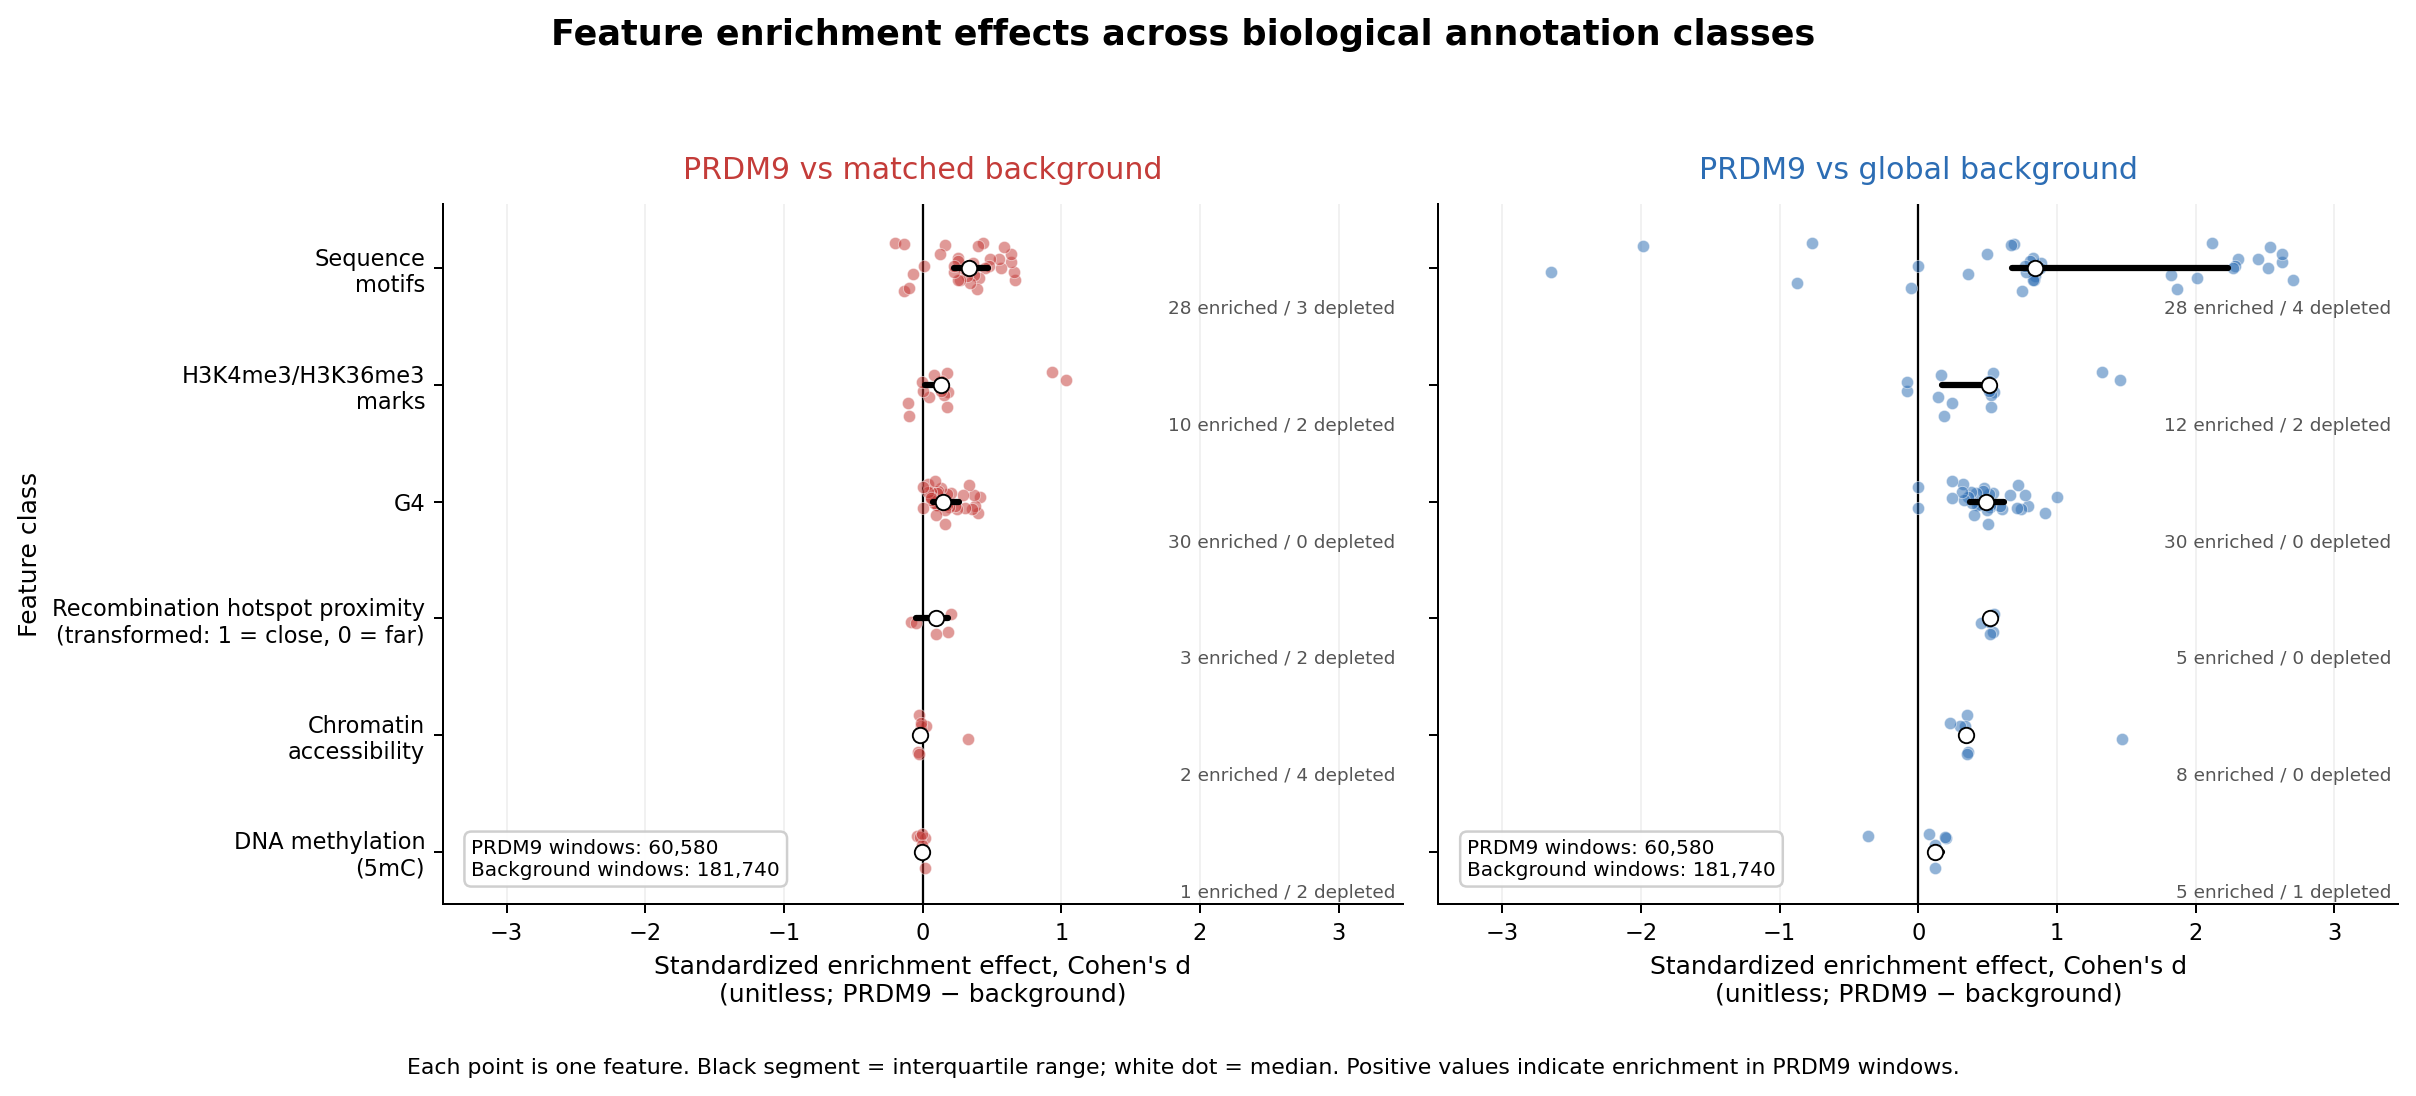

In [33]:
# ------------------------------------------------------------------
# Figure 1 — all-feature enrichment effect distributions
# ------------------------------------------------------------------
def make_block_distribution_figure_publication(res_a, res_b, out_path):
    res_a = _filter_public_blocks(res_a)
    res_b = _filter_public_blocks(res_b)
    order = PLOT_BLOCK_ORDER

    all_vals = pd.concat([res_a["cohens_d"], res_b["cohens_d"]], ignore_index=True).dropna()
    lim = max(0.35, float(np.nanpercentile(np.abs(all_vals), 99)) * 1.20)
    lim = min(lim, max(0.5, float(np.nanmax(np.abs(all_vals))) * 1.05))
    xlim = (-lim * 1.22, lim * 1.22)

    fig, axes = plt.subplots(1, 2, figsize=(13.8, 6.2), sharey=True)

    for ax, res, bg_name in [
        (axes[0], res_a, "datasetA_matched"),
        (axes[1], res_b, "datasetB_global"),
    ]:
        color = DATASET_COLORS[bg_name]

        for i, block in enumerate(order):
            sub = res.loc[res["_block_str"] == block].copy()
            if sub.empty:
                continue

            vals = sub["cohens_d"].to_numpy(dtype=np.float64)
            y = np.full(len(vals), i, dtype=np.float64) + _jitter(len(vals), scale=0.095, seed=17 + i)

            ax.scatter(
                vals, y,
                s=24,
                color=color,
                alpha=0.52,
                edgecolor="white",
                linewidth=0.35,
                zorder=3,
            )

            q1, med, q3 = np.quantile(vals, [0.25, 0.5, 0.75])
            ax.plot([q1, q3], [i, i], color="black", lw=2.5, solid_capstyle="round", zorder=5)
            ax.scatter([med], [i], s=38, color="white", edgecolor="black", linewidth=0.75, zorder=6)

            n_enr = int(((sub["significant"]) & (sub["direction"] == "enriched")).sum())
            n_dep = int(((sub["significant"]) & (sub["direction"] == "depleted")).sum())
            ax.text(
                xlim[1] * 0.985,
                i + 0.35,
                f"{n_enr} enriched / {n_dep} depleted",
                ha="right",
                va="center",
                fontsize=7.4,
                color="#555555",
            )

        ax.axvline(0, color="black", lw=0.9)
        ax.set_xlim(*xlim)
        ax.set_ylim(len(order) - 0.55, -0.55)
        ax.grid(True, axis="x", alpha=0.20, lw=0.65)
        ax.set_title(PUBLIC_DATASET_TITLES[bg_name], color=color, pad=10)
        ax.set_xlabel("Standardized enrichment effect, Cohen's d\n(PRDM9 − background)")
        ax.set_yticks(range(len(order)))
        ax.set_yticklabels([PUBLIC_BLOCK_LABELS[b] for b in order])
        _despine(ax)

        n_pos = int(res["n_prdm9_windows"].iloc[0])
        n_bg = int(res["n_background_windows"].iloc[0])
        ax.text(
            0.03,
            0.035,
            f"PRDM9 windows: {n_pos:,}\nBackground windows: {n_bg:,}",
            transform=ax.transAxes,
            ha="left",
            va="bottom",
            fontsize=8,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="#cccccc", alpha=0.94),
        )

    axes[0].set_ylabel("Feature class")

    fig.suptitle(
        "Feature enrichment effects across biological annotation classes",
        y=0.985,
        fontsize=14,
        fontweight="bold",
    )
    fig.text(
        0.5,
        0.035,
        "Each point is one feature. Black segment = interquartile range; white dot = median. "
        "Positive values indicate enrichment in PRDM9 windows.",
        ha="center",
        va="bottom",
        fontsize=8.8,
    )

    fig.tight_layout(rect=[0.02, 0.075, 1, 0.94])
    _save_publication_figure(fig, out_path)
    plt.show()


make_block_distribution_figure_publication(
    res_A,
    res_B,
    FIGDIR / "figure01_block_effect_distributions_publication.png",
)

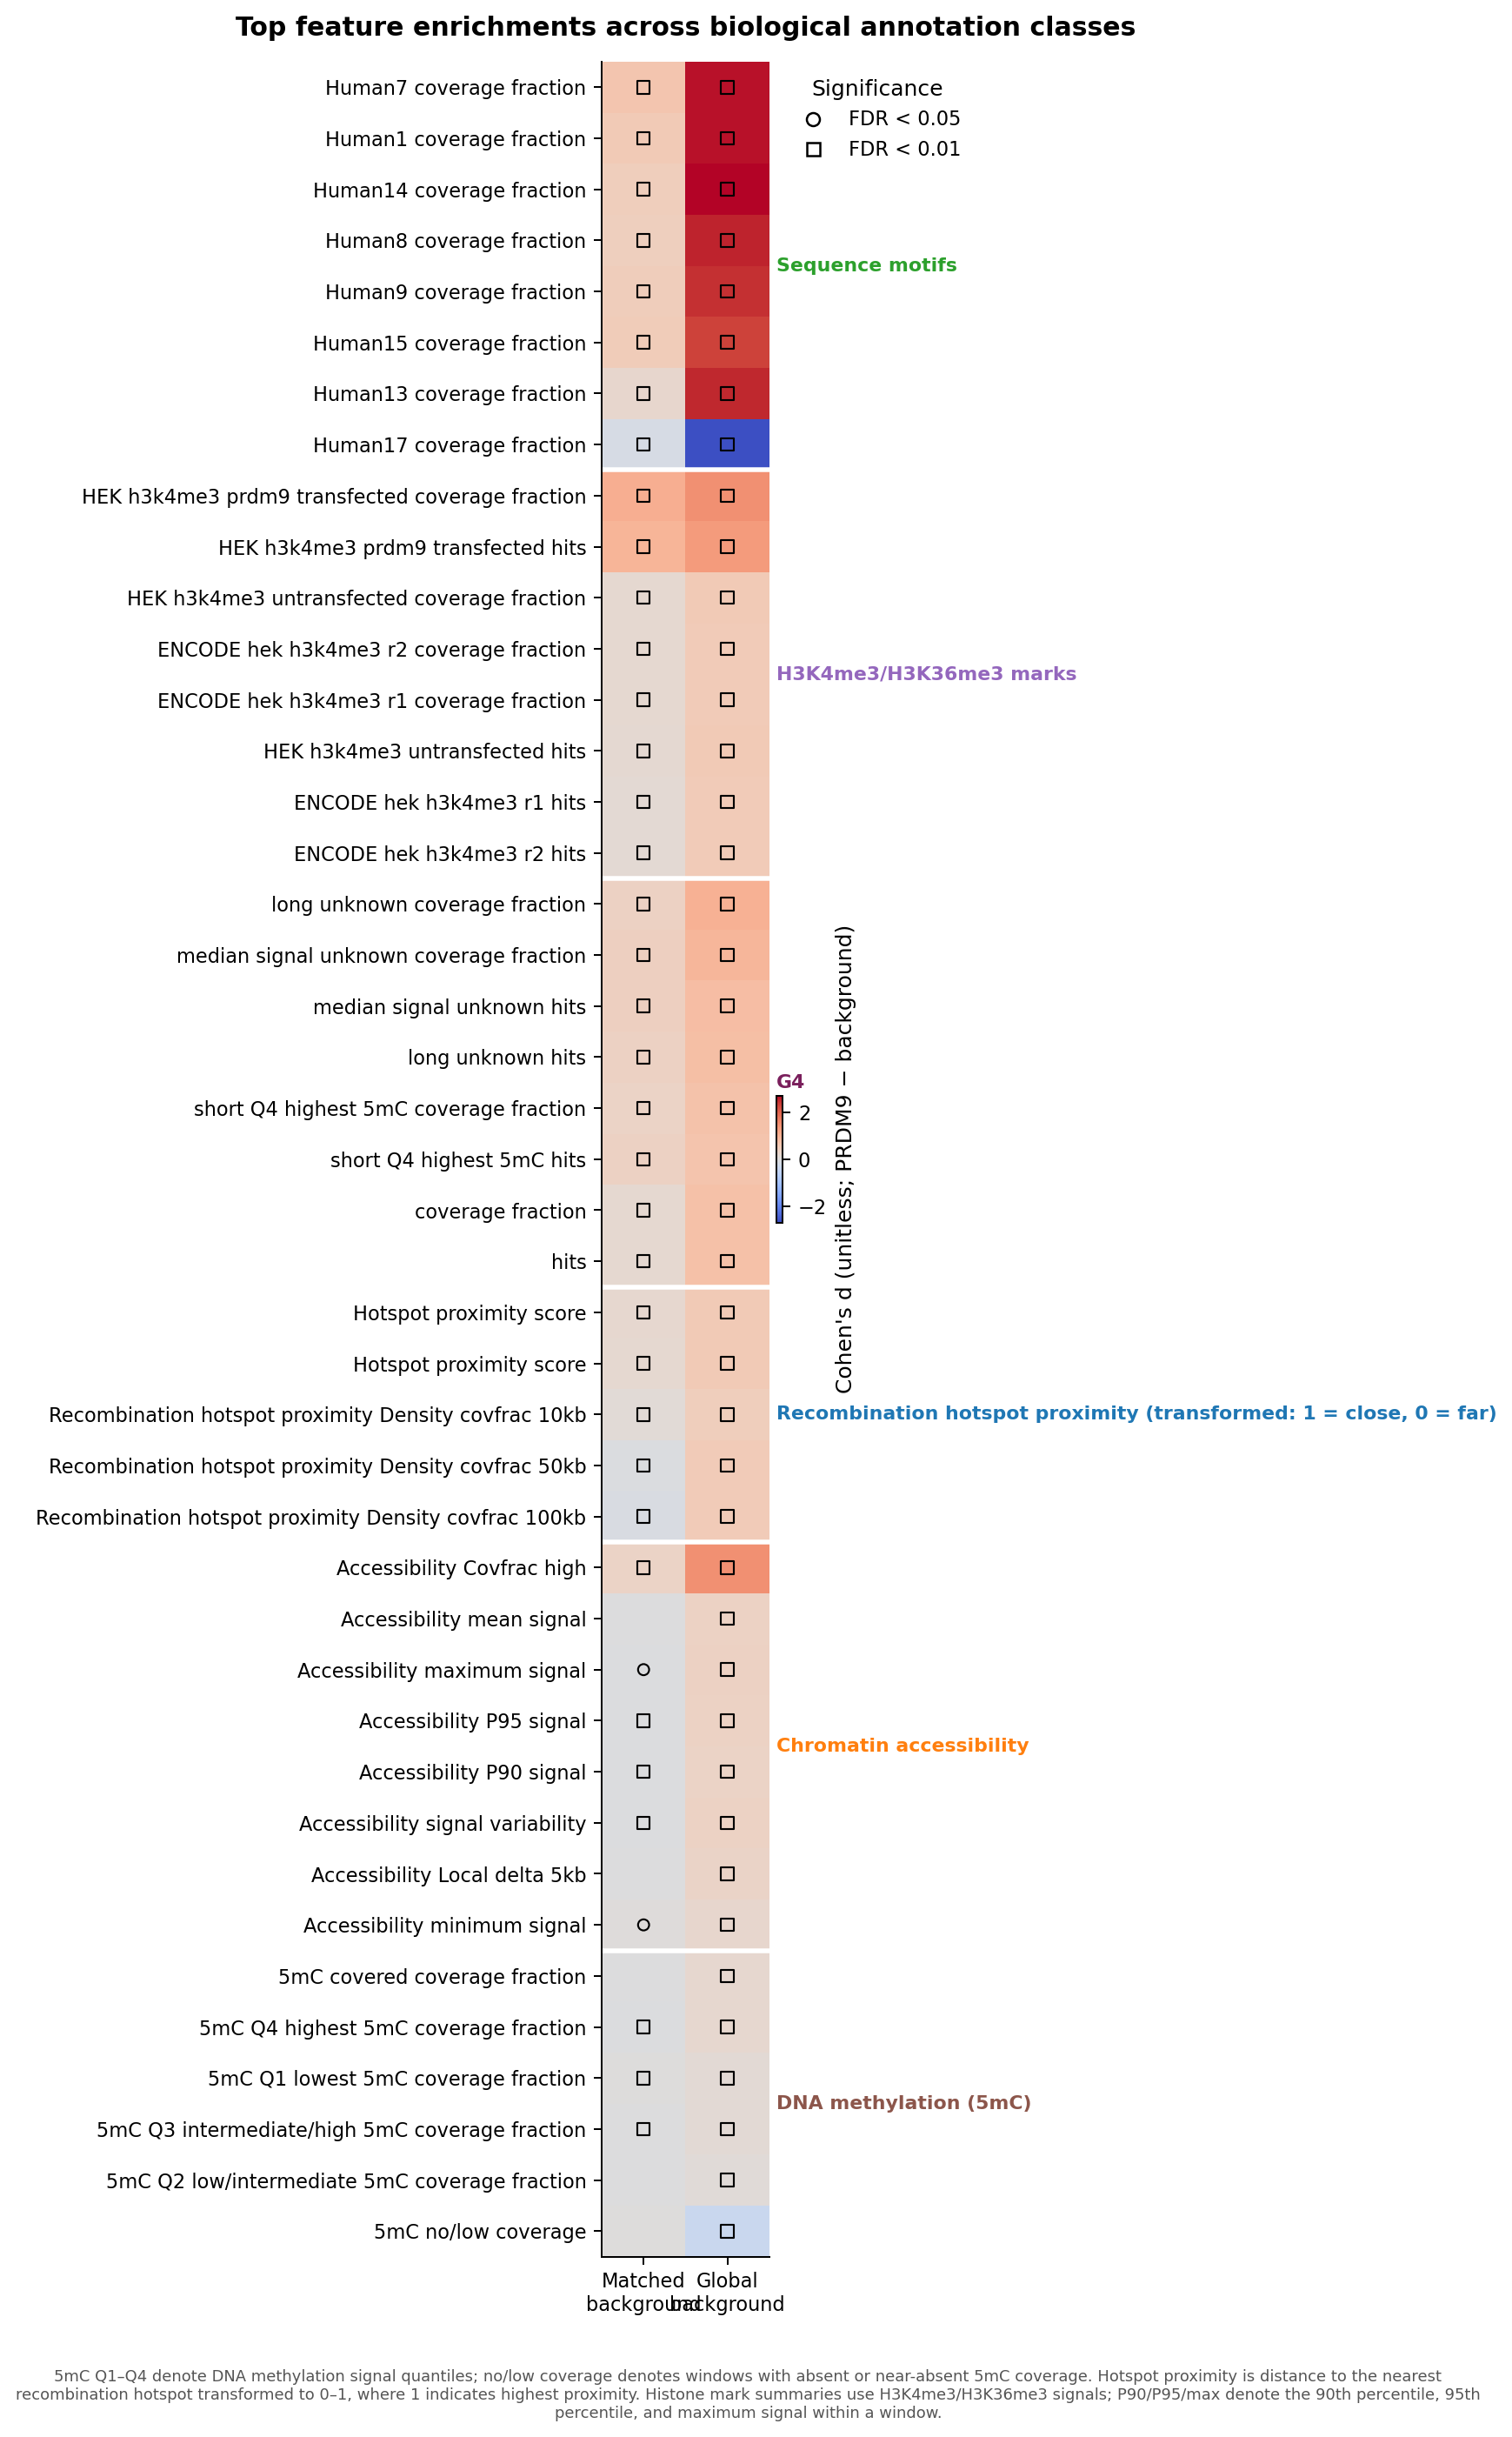

In [34]:
# ------------------------------------------------------------------
# Figure 2 — top feature heatmap
# ------------------------------------------------------------------
def make_top_feature_heatmap_publication(heatmap_df, out_path):
    if heatmap_df.empty:
        logger.warning("Heatmap dataframe is empty; skipping %s", out_path)
        return

    df = _filter_public_blocks(heatmap_df)
    if df.empty:
        logger.warning("Heatmap dataframe has no public blocks after filtering; skipping %s", out_path)
        return

    df["public_feature"] = df["feature"].map(public_feature_label)
    df["_block_rank"] = df["_block_str"].map({b: i for i, b in enumerate(PLOT_BLOCK_ORDER)})
    df["_mean_effect"] = df[["cohens_d_A", "cohens_d_B"]].mean(axis=1)
    df["_max_abs_effect"] = df[["cohens_d_A", "cohens_d_B"]].abs().max(axis=1)

    # Visual-only ordering: class order strongest-to-weakest, then strongest enrichment.
    df = (
        df.sort_values(
            ["_block_rank", "_mean_effect", "_max_abs_effect", "min_fdr"],
            ascending=[True, False, False, True],
            kind="mergesort",
        )
        .reset_index(drop=True)
    )

    rows = df["public_feature"].tolist()
    data = df[["cohens_d_A", "cohens_d_B"]].to_numpy(dtype=np.float64)
    fdrs = df[["fdr_final_A", "fdr_final_B"]].to_numpy(dtype=np.float64)
    vmax = max(0.5, float(np.nanmax(np.abs(data))))

    fig_h = max(7.0, 0.31 * len(rows) + 2.7)
    fig, ax = plt.subplots(figsize=(9.4, fig_h))

    im = ax.imshow(
        data,
        aspect="auto",
        cmap="coolwarm",
        norm=TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax),
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Matched\nbackground", "Global\nbackground"])
    ax.set_yticks(np.arange(len(rows)))
    ax.set_yticklabels(rows)
    ax.set_title("Top feature enrichments across biological annotation classes", pad=12, fontweight="bold")

    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            if fdrs[i, j] < 0.01:
                ax.scatter(j, i, s=34, marker="s", facecolor="none", edgecolor="black", linewidth=0.85)
            elif fdrs[i, j] < 0.05:
                ax.scatter(j, i, s=26, marker="o", facecolor="none", edgecolor="black", linewidth=0.85)

    y0 = 0
    for block in PLOT_BLOCK_ORDER:
        sub = df.loc[df["_block_str"] == block]
        if sub.empty:
            continue
        y1 = y0 + len(sub)
        if y0 > 0:
            ax.axhline(y0 - 0.5, color="white", lw=2.2)
        ax.text(
            1.04,
            (y0 + y1 - 1) / 2.0,
            PUBLIC_BLOCK_LABELS[block].replace("\n", " "),
            transform=ax.get_yaxis_transform(),
            ha="left",
            va="center",
            fontsize=8.8,
            color=PUBLIC_BLOCK_COLORS[block],
            fontweight="bold",
        )
        y0 = y1

    cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.04)
    cbar.set_label("Cohen's d (PRDM9 − background)")

    legend_handles = [
        Line2D([0], [0], marker="o", color="none", markeredgecolor="black", markerfacecolor="none", label="FDR < 0.05", markersize=6),
        Line2D([0], [0], marker="s", color="none", markeredgecolor="black", markerfacecolor="none", label="FDR < 0.01", markersize=6),
    ]
    ax.legend(
        handles=legend_handles,
        loc="upper left",
        bbox_to_anchor=(1.04, 1.0),
        frameon=False,
        title="Significance",
    )

    fig.text(
        0.5,
        0.012,
        PUBLIC_NOTES,
        ha="center",
        va="bottom",
        fontsize=7.2,
        color="#555555",
        wrap=True,
    )

    fig.tight_layout(rect=[0, 0.045, 1, 0.98])
    _save_publication_figure(fig, out_path)
    plt.show()


make_top_feature_heatmap_publication(
    heatmap_features,
    FIGDIR / "figure02_top_feature_heatmap_AB_publication.png",
)

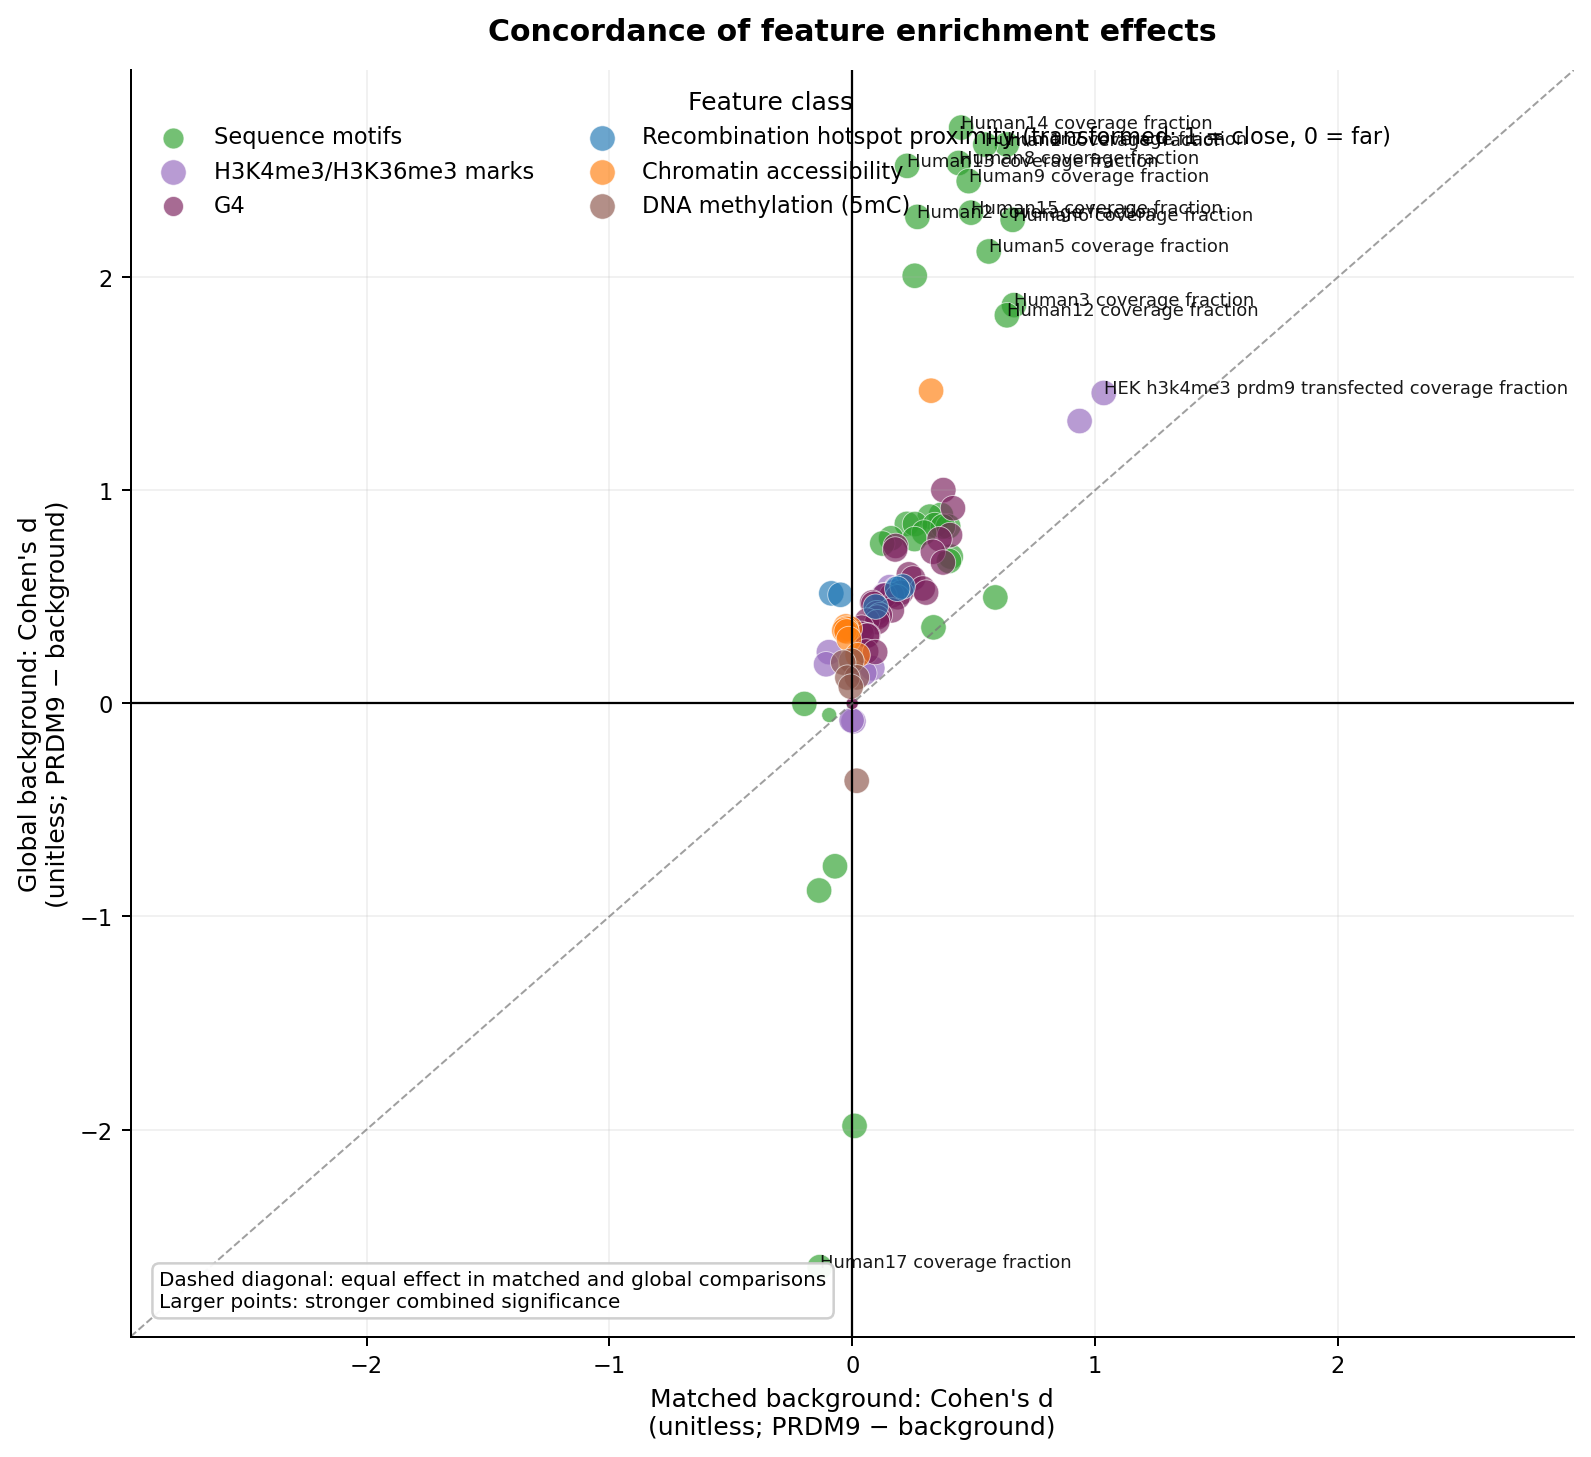

In [35]:
# ------------------------------------------------------------------
# Figure 3 — matched/global concordance
# ------------------------------------------------------------------
def make_concordance_figure_publication(merged, labels_df, out_path):
    merged = _filter_public_blocks(merged)
    labels_df = _filter_public_blocks(labels_df)

    fig, ax = plt.subplots(figsize=(9.2, 8.2))

    vals = merged[["cohens_d_A", "cohens_d_B"]].to_numpy(dtype=np.float64)
    vmax = max(0.5, float(np.nanmax(np.abs(vals))))
    lim = vmax * 1.10

    for block in PLOT_BLOCK_ORDER:
        sub = merged.loc[merged["_block_str"] == block]
        if sub.empty:
            continue

        point_size = 24 + 15 * (-np.log10(sub["min_fdr"].clip(lower=1e-300))).clip(upper=8)
        ax.scatter(
            sub["cohens_d_A"],
            sub["cohens_d_B"],
            s=point_size,
            color=PUBLIC_BLOCK_COLORS[block],
            alpha=0.66,
            edgecolor="white",
            linewidth=0.35,
            label=PUBLIC_BLOCK_LABELS[block].replace("\n", " "),
        )

    for _, r in labels_df.iterrows():
        ax.text(
            r["cohens_d_A"],
            r["cohens_d_B"],
            public_feature_label(r["feature"]),
            fontsize=7.2,
            alpha=0.90,
        )

    ax.axvline(0, color="black", lw=0.9)
    ax.axhline(0, color="black", lw=0.9)
    ax.plot([-lim, lim], [-lim, lim], color="#777777", lw=0.8, ls="--", alpha=0.7)

    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.grid(True, alpha=0.20, lw=0.65)

    ax.set_xlabel("Matched background: Cohen's d\n(PRDM9 − background)")
    ax.set_ylabel("Global background: Cohen's d\n(PRDM9 − background)")
    ax.set_title("Concordance of feature enrichment effects", pad=12, fontweight="bold")

    ax.legend(loc="upper left", frameon=False, ncol=2, title="Feature class")

    ax.text(
        0.02,
        0.02,
        "Dashed diagonal: equal effect in matched and global comparisons\nLarger points: stronger combined significance",
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=8,
        bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="#cccccc", alpha=0.94),
    )

    _despine(ax)
    fig.tight_layout()
    _save_publication_figure(fig, out_path)
    plt.show()


make_concordance_figure_publication(
    merged_res,
    concordance_labels,
    FIGDIR / "figure03_concordance_scatter_AB_publication.png",
)

/tmp/ipykernel_195/1984327369.py:162: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0.02, 0.065, 1, 0.94])


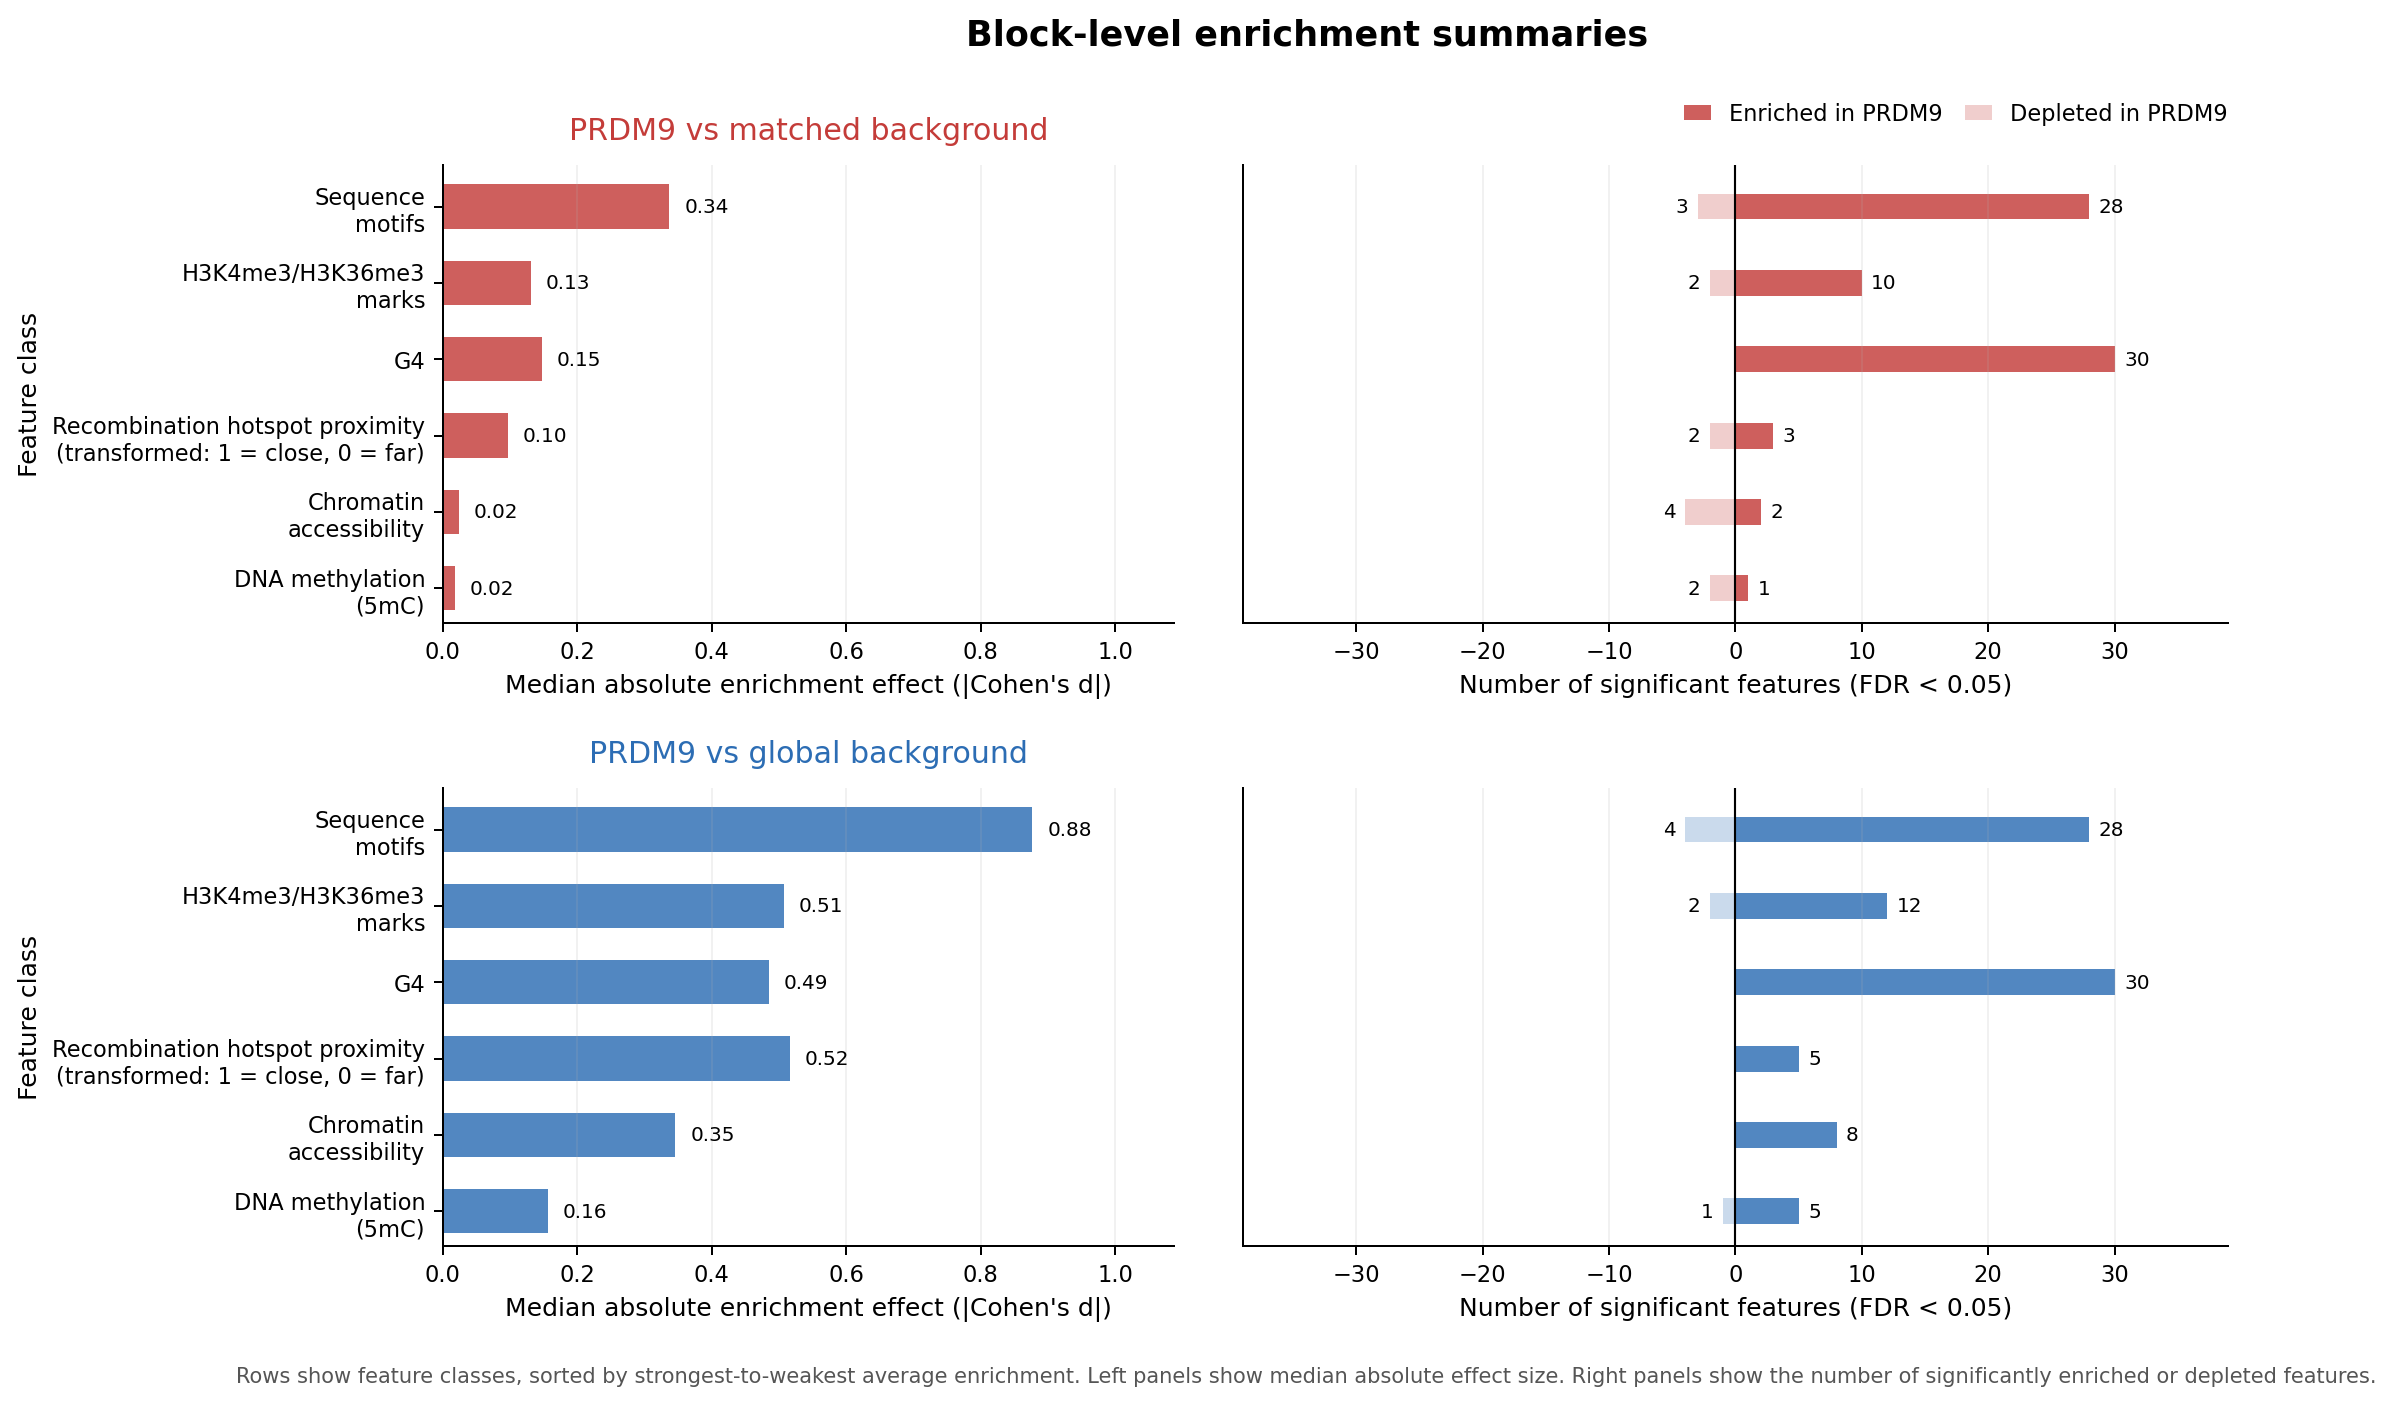

In [43]:
# ------------------------------------------------------------------
# Figure 4 — block-level enrichment summaries
# ------------------------------------------------------------------
# ------------------------------------------------------------------
# Figure 4 — block-level enrichment summaries
# ------------------------------------------------------------------
def make_block_summary_figure_publication(block_a, block_b, out_path):
    a = block_a.copy()
    b = block_b.copy()
    a["_block_str"] = a["block"].astype(str)
    b["_block_str"] = b["block"].astype(str)

    a = a.loc[a["_block_str"].isin(PLOT_BLOCK_ORDER)].set_index("_block_str").reindex(PLOT_BLOCK_ORDER)
    b = b.loc[b["_block_str"].isin(PLOT_BLOCK_ORDER)].set_index("_block_str").reindex(PLOT_BLOCK_ORDER)

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(12.8, 7.8),
        sharey="row",   # important: share only within each row
        gridspec_kw={
            "width_ratios": [0.95, 1.28],
            "hspace": 0.36,
            "wspace": 0.08,
        },
    )

    rows = [
        (a, "datasetA_matched", axes[0, 0], axes[0, 1]),
        (b, "datasetB_global", axes[1, 0], axes[1, 1]),
    ]

    y = np.arange(len(PLOT_BLOCK_ORDER))
    ylabels = [PUBLIC_BLOCK_LABELS[x] for x in PLOT_BLOCK_ORDER]

    max_median_abs = max(
        float(np.nanmax(a["median_abs_d"].to_numpy(dtype=np.float64))),
        float(np.nanmax(b["median_abs_d"].to_numpy(dtype=np.float64))),
        0.1,
    )
    max_count = max(
        float(np.nanmax(a[["n_sig_enriched", "n_sig_depleted"]].to_numpy(dtype=np.float64))),
        float(np.nanmax(b[["n_sig_enriched", "n_sig_depleted"]].to_numpy(dtype=np.float64))),
        1.0,
    )

    for summary_df, bg_name, ax_mag, ax_count in rows:
        color = DATASET_COLORS[bg_name]
        med = summary_df["median_abs_d"].to_numpy(dtype=np.float64)
        enr = summary_df["n_sig_enriched"].fillna(0).to_numpy(dtype=np.float64)
        dep = summary_df["n_sig_depleted"].fillna(0).to_numpy(dtype=np.float64)

        # ------------------------------
        # Left: summary magnitude
        # ------------------------------
        ax_mag.barh(y, med, color=color, alpha=0.82, height=0.58)

        for yi, val in zip(y, med):
            if np.isfinite(val):
                ax_mag.text(
                    val + max_median_abs * 0.025,
                    yi,
                    f"{val:.2f}",
                    va="center",
                    ha="left",
                    fontsize=8,
                )

        ax_mag.set_xlim(0, max_median_abs * 1.24)
        ax_mag.set_yticks(y)
        ax_mag.set_yticklabels(ylabels)
        ax_mag.tick_params(axis="y", labelleft=True)
        ax_mag.set_ylim(len(PLOT_BLOCK_ORDER) - 0.55, -0.55)
        ax_mag.grid(axis="x", alpha=0.20, lw=0.65)
        ax_mag.set_xlabel("Median absolute enrichment effect (|Cohen's d|)")
        ax_mag.set_ylabel("Feature class")
        ax_mag.set_title(PUBLIC_DATASET_TITLES[bg_name], color=color, pad=10)
        _despine(ax_mag)

        # ------------------------------
        # Right: significant feature counts
        # ------------------------------
        ax_count.barh(
            y,
            enr,
            color=color,
            alpha=0.82,
            height=0.34,
            label=ENRICHED_LABEL,
        )
        ax_count.barh(
            y,
            -dep,
            color=color,
            alpha=0.25,
            height=0.34,
            label=DEPLETED_LABEL,
        )
        ax_count.axvline(0, color="black", lw=0.85)

        for yi, val in zip(y, enr):
            if val > 0:
                ax_count.text(
                    val + max_count * 0.025,
                    yi,
                    f"{int(val)}",
                    va="center",
                    ha="left",
                    fontsize=8,
                )

        for yi, val in zip(y, dep):
            if val > 0:
                ax_count.text(
                    -val - max_count * 0.025,
                    yi,
                    f"{int(val)}",
                    va="center",
                    ha="right",
                    fontsize=8,
                )

        ax_count.set_xlim(-max_count * 1.30, max_count * 1.30)
        ax_count.set_yticks(y)

        # Important: do NOT call set_yticklabels([]) on a shared y-axis.
        # This hides labels only on the right subplot without deleting labels
        # from the left subplot.
        ax_count.tick_params(axis="y", labelleft=False, left=False)

        ax_count.set_ylim(len(PLOT_BLOCK_ORDER) - 0.55, -0.55)
        ax_count.grid(axis="x", alpha=0.20, lw=0.65)
        ax_count.set_xlabel("Number of significant features (FDR < 0.05)")
        _despine(ax_count)

    axes[0, 1].legend(
        frameon=False,
        loc="upper right",
        bbox_to_anchor=(1.02, 1.18),
        ncol=2,
        handlelength=1.2,
        columnspacing=1.0,
    )

    fig.suptitle(
        "Block-level enrichment summaries",
        y=0.985,
        fontsize=14,
        fontweight="bold",
    )
    fig.text(
        0.5,
        0.01,
        "Rows show feature classes, sorted by strongest-to-weakest average enrichment. "
        "Left panels show median absolute effect size. Right panels show the number of significantly enriched or depleted features.",
        ha="center",
        va="bottom",
        fontsize=8.4,
        color="#555555",
    )

    fig.tight_layout(rect=[0.02, 0.065, 1, 0.94])
    _save_publication_figure(fig, out_path)
    plt.show()


make_block_summary_figure_publication(
    block_A,
    block_B,
    FIGDIR / "figure04_block_summary_publication.png",
)

In [55]:
# ------------------------------------------------------------------
# Better publication labels for per-class breakdowns
# Rendering only; upstream feature/statistics logic unchanged.
# ------------------------------------------------------------------

PUBLIC_BLOCK_LABELS["histones"] = "H3K4me3/H3K36me3\nhistone marks"


def _contains_any(s, patterns):
    s = str(s).lower()
    return any(p in s for p in patterns)


def _metric_from_feature(feature_name):
    """
    Extract a readable summary statistic from a feature name.
    Used only for labels.
    """
    f = str(feature_name).lower()

    metric_patterns = [
        ("p95", "P95 signal"),
        ("p90", "P90 signal"),
        ("max", "maximum signal"),
        ("median", "median signal"),
        ("mean", "mean signal"),
        ("std", "signal variability"),
        ("min", "minimum signal"),
        ("covfrac", "coverage fraction"),
        ("coverage_fraction", "coverage fraction"),
        ("coverage_frac", "coverage fraction"),
        ("fraction_covered", "coverage fraction"),
        ("covered_fraction", "coverage fraction"),
        ("covered", "covered fraction"),
        ("hits", "hit count"),
    ]

    for pat, label in metric_patterns:
        if pat in f:
            return label

    return ""


def _condition_from_feature(feature_name):
    f = str(feature_name).lower()

    # order matters: untransfected contains "transfected"
    if "untransfected" in f:
        return "untransfected"
    if "transfected" in f:
        return "PRDM9-transfected"
    if "encode" in f:
        return "ENCODE"
    if "hek293t" in f:
        return "HEK293T"
    if "hek293" in f:
        return "HEK293"
    if "hek" in f:
        return "HEK"

    return ""


def _mark_from_feature(feature_name):
    f = str(feature_name).lower()

    if "h3k4me3" in f or "k4me3" in f:
        return "H3K4me3"
    if "h3k36me3" in f or "k36me3" in f:
        return "H3K36me3"

    return ""


def public_feature_label(feature_name):
    """
    Figure-only label cleanup.
    Does not change feature IDs or statistics.
    """
    feature_name = str(feature_name)
    block = guess_block(feature_name)
    parts = feature_name.split("__")
    body = parts[1:] if len(parts) > 1 else parts

    if block == "methylation":
        joined = " ".join(body).lower()
        if "no_coverage" in joined or ("no" in joined and "coverage" in joined):
            return "5mC no/low coverage"

        metric = _metric_from_feature(feature_name)
        if "q1" in joined:
            return "5mC Q1 lowest methylation"
        if "q2" in joined:
            return "5mC Q2 low/intermediate methylation"
        if "q3" in joined:
            return "5mC Q3 intermediate/high methylation"
        if "q4" in joined:
            return "5mC Q4 highest methylation"
        return "5mC " + (metric if metric else "signal")

    if block == "histones":
        mark = _mark_from_feature(feature_name)
        cond = _condition_from_feature(feature_name)
        metric = _metric_from_feature(feature_name)

        pieces = [x for x in [mark, cond, metric] if x]
        if pieces:
            return " ".join(pieces)

        label = " ".join(_public_token(x) for x in body)
        label = re.sub(r"\s+", " ", label).strip()
        label = label.replace("H3K4ME3", "H3K4me3").replace("H3K36ME3", "H3K36me3")
        label = label.replace("Encode", "ENCODE").replace("Hek", "HEK")
        return label

    if block == "recombination":
        metric = _metric_from_feature(feature_name)

        # Avoid duplicate "Hotspot proximity score" labels.
        # Keep the shared biological meaning but distinguish the window summary.
        if metric:
            return f"Hotspot proximity — {metric}"
        return "Hotspot proximity score"

    if block == "accessibility":
        cond = _condition_from_feature(feature_name)
        metric = _metric_from_feature(feature_name)

        pieces = ["Chromatin accessibility"]
        if cond:
            pieces.append(cond)
        if metric:
            pieces.append(metric)

        return " — ".join(pieces)

    if block == "motifs":
        metric = _metric_from_feature(feature_name)
        label = " ".join(_public_token(x) for x in body)
        label = re.sub(r"\s+", " ", label).strip()

        # Prefer readable motif name + coverage fraction.
        label = label.replace("Covfrac", "coverage fraction")
        label = label.replace("Coverage fraction", "coverage fraction")
        label = label.replace("Hits", "hit count")

        if metric and metric not in label:
            label = f"{label} — {metric}"

        return label

    if block == "g4":
        return " ".join(_public_token(x) for x in body)

    return pretty_feature(feature_name)


def _block_specific_note(block):
    if block == "methylation":
        return (
            "5mC Q1–Q4 are quantiles of DNA methylation signal; "
            "no/low coverage denotes absent or near-absent methylation coverage."
        )

    if block == "histones":
        return (
            ""
        )

    if block == "recombination":
        return (
            ""
        )

    if block == "accessibility":
        return (
            "Chromatin accessibility features summarize signal across each window. "
            "Coverage fraction is the fraction of the window with signal; "
            "P90/P95/maximum denote the 90th percentile, 95th percentile, and maximum signal."
        )

    if block == "motifs":
        return (
            "Sequence motif breakdown shows coverage-fraction features only."
        )

    return "Rows are sorted from strongest-to-weakest average enrichment across the two background comparisons."


def _make_unique_labels(features):
    """
    Avoid duplicate y-axis labels after public relabeling.
    If two raw features collapse to the same readable label, append a short raw suffix.
    """
    labels = [public_feature_label(f) for f in features]
    counts = pd.Series(labels).value_counts().to_dict()

    if all(counts[x] == 1 for x in labels):
        return labels

    out = []
    seen = {}

    for raw, label in zip(features, labels):
        if counts[label] == 1:
            out.append(label)
            continue

        seen[label] = seen.get(label, 0) + 1
        suffix = str(raw).split("__")[-1]
        suffix = suffix.replace("_", " ")
        suffix = suffix[:38]
        out.append(f"{label} [{suffix}]")

    return out

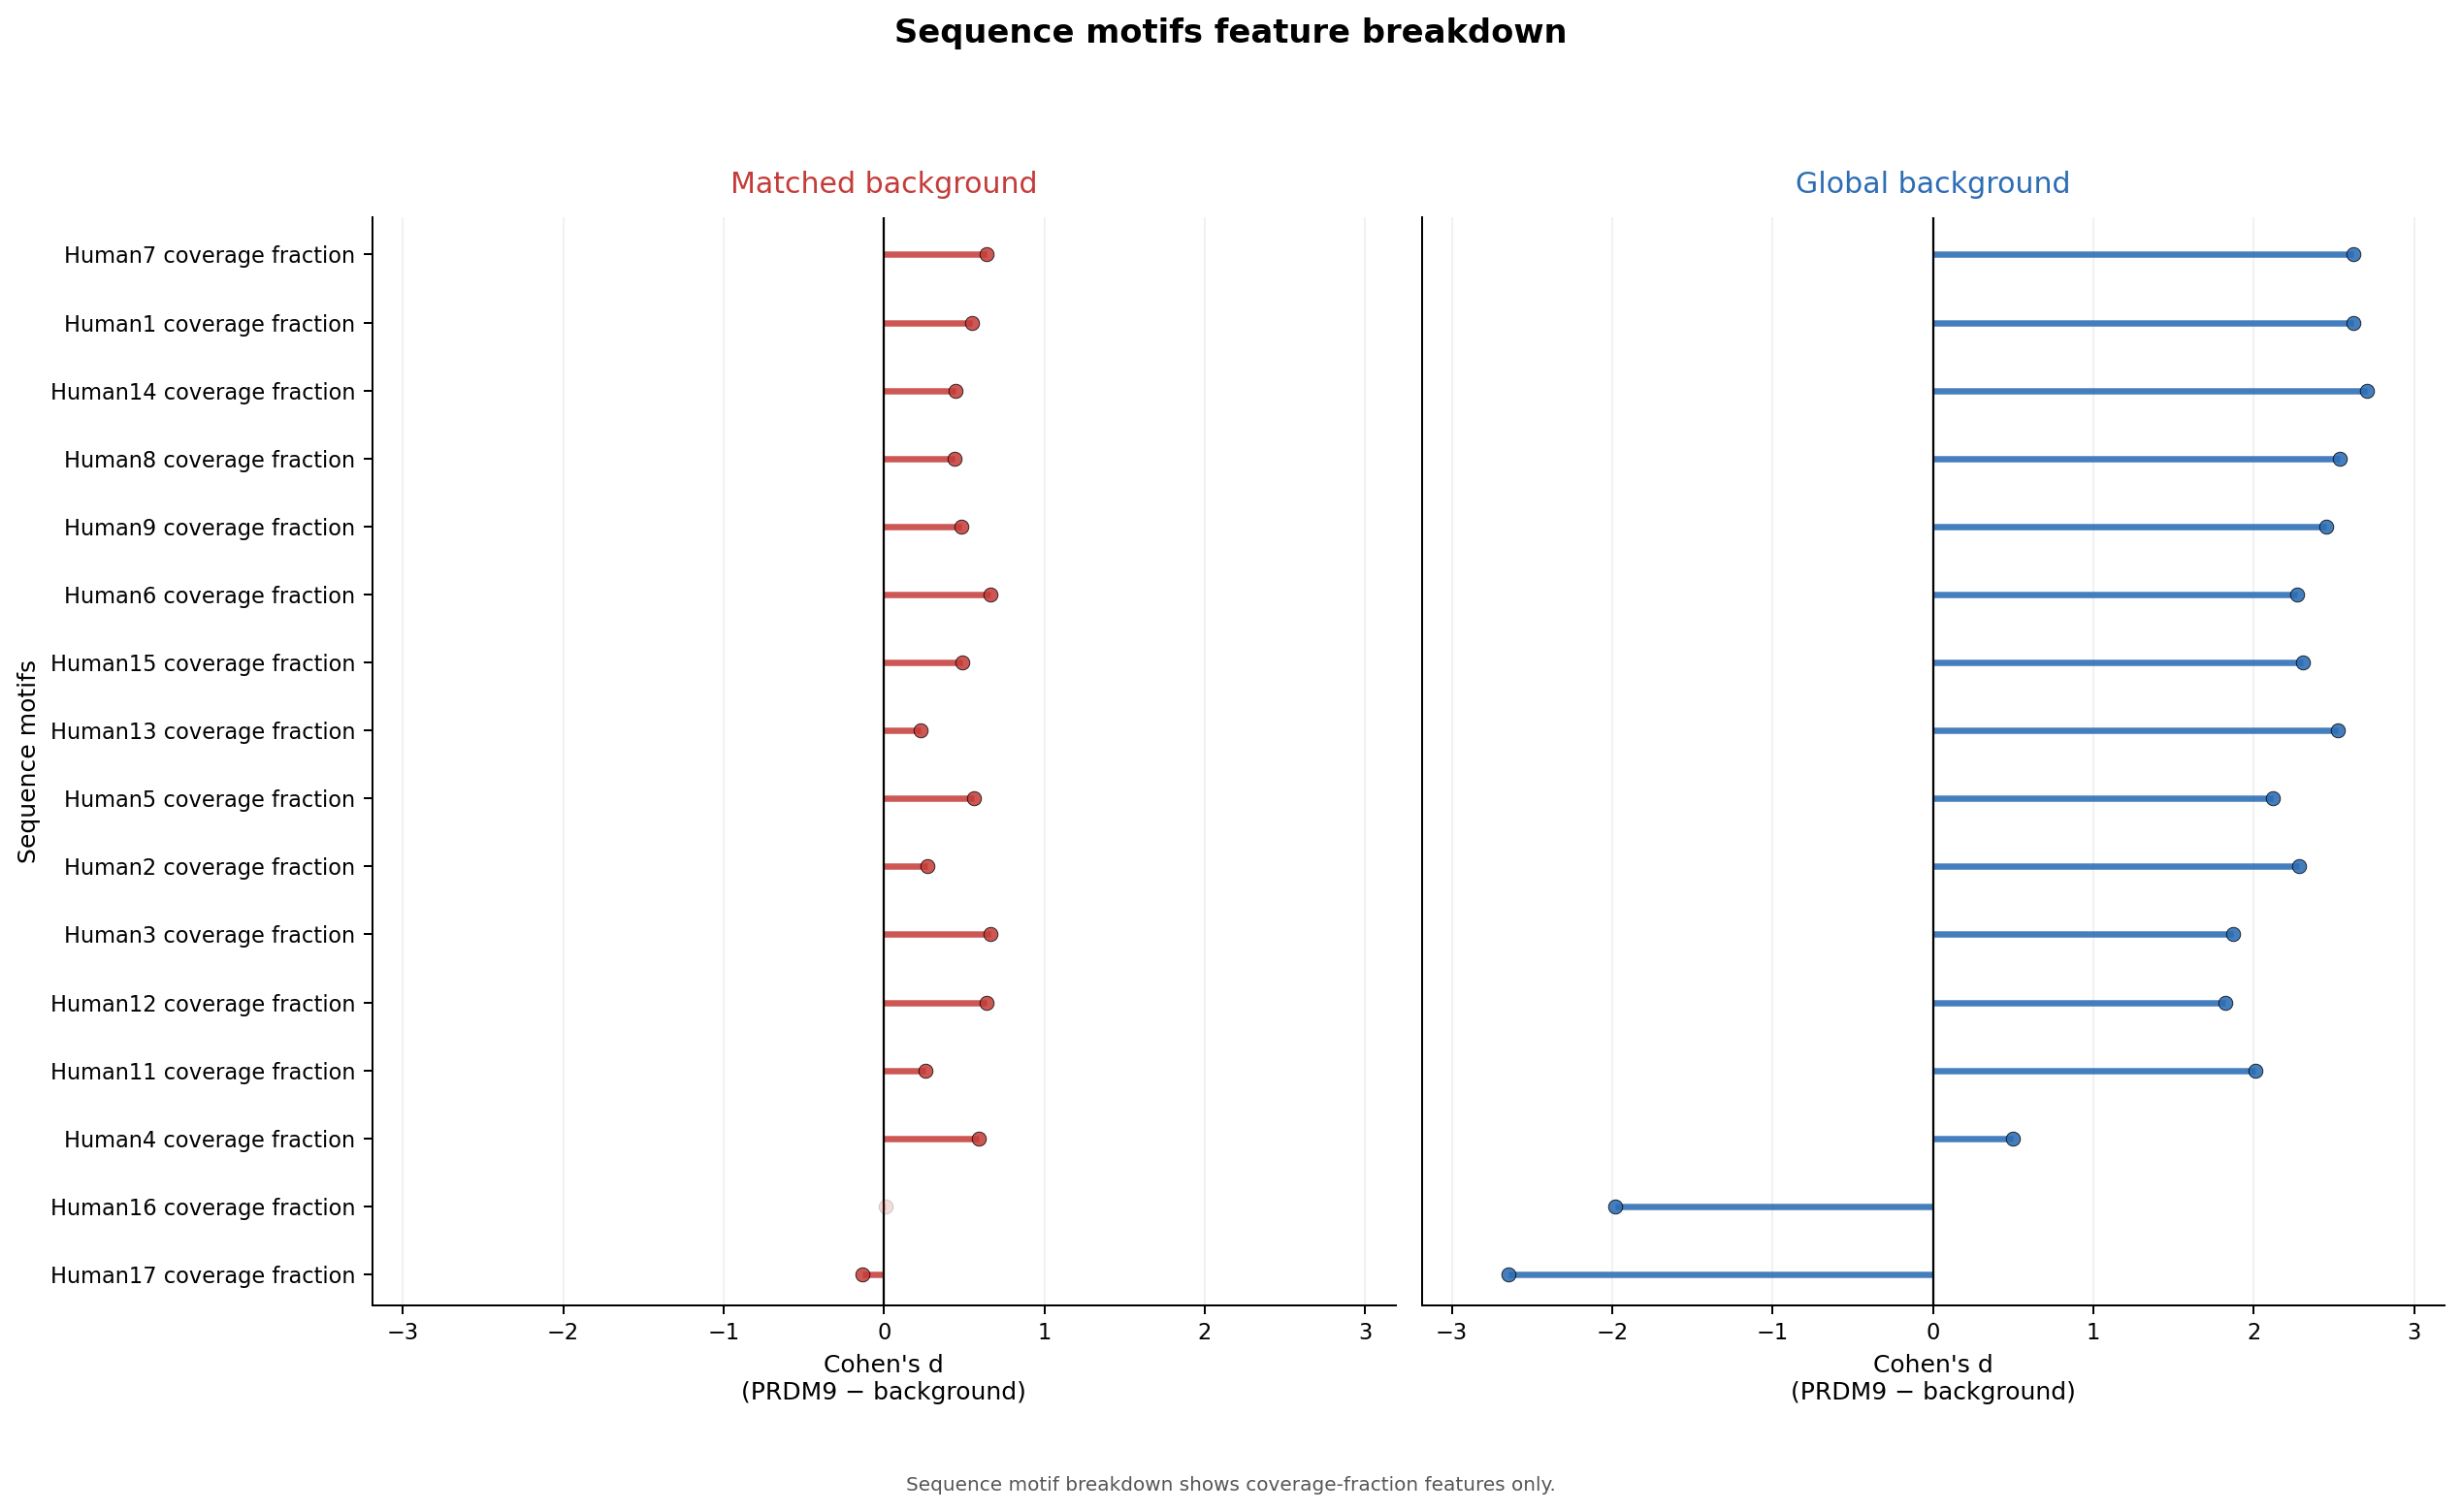

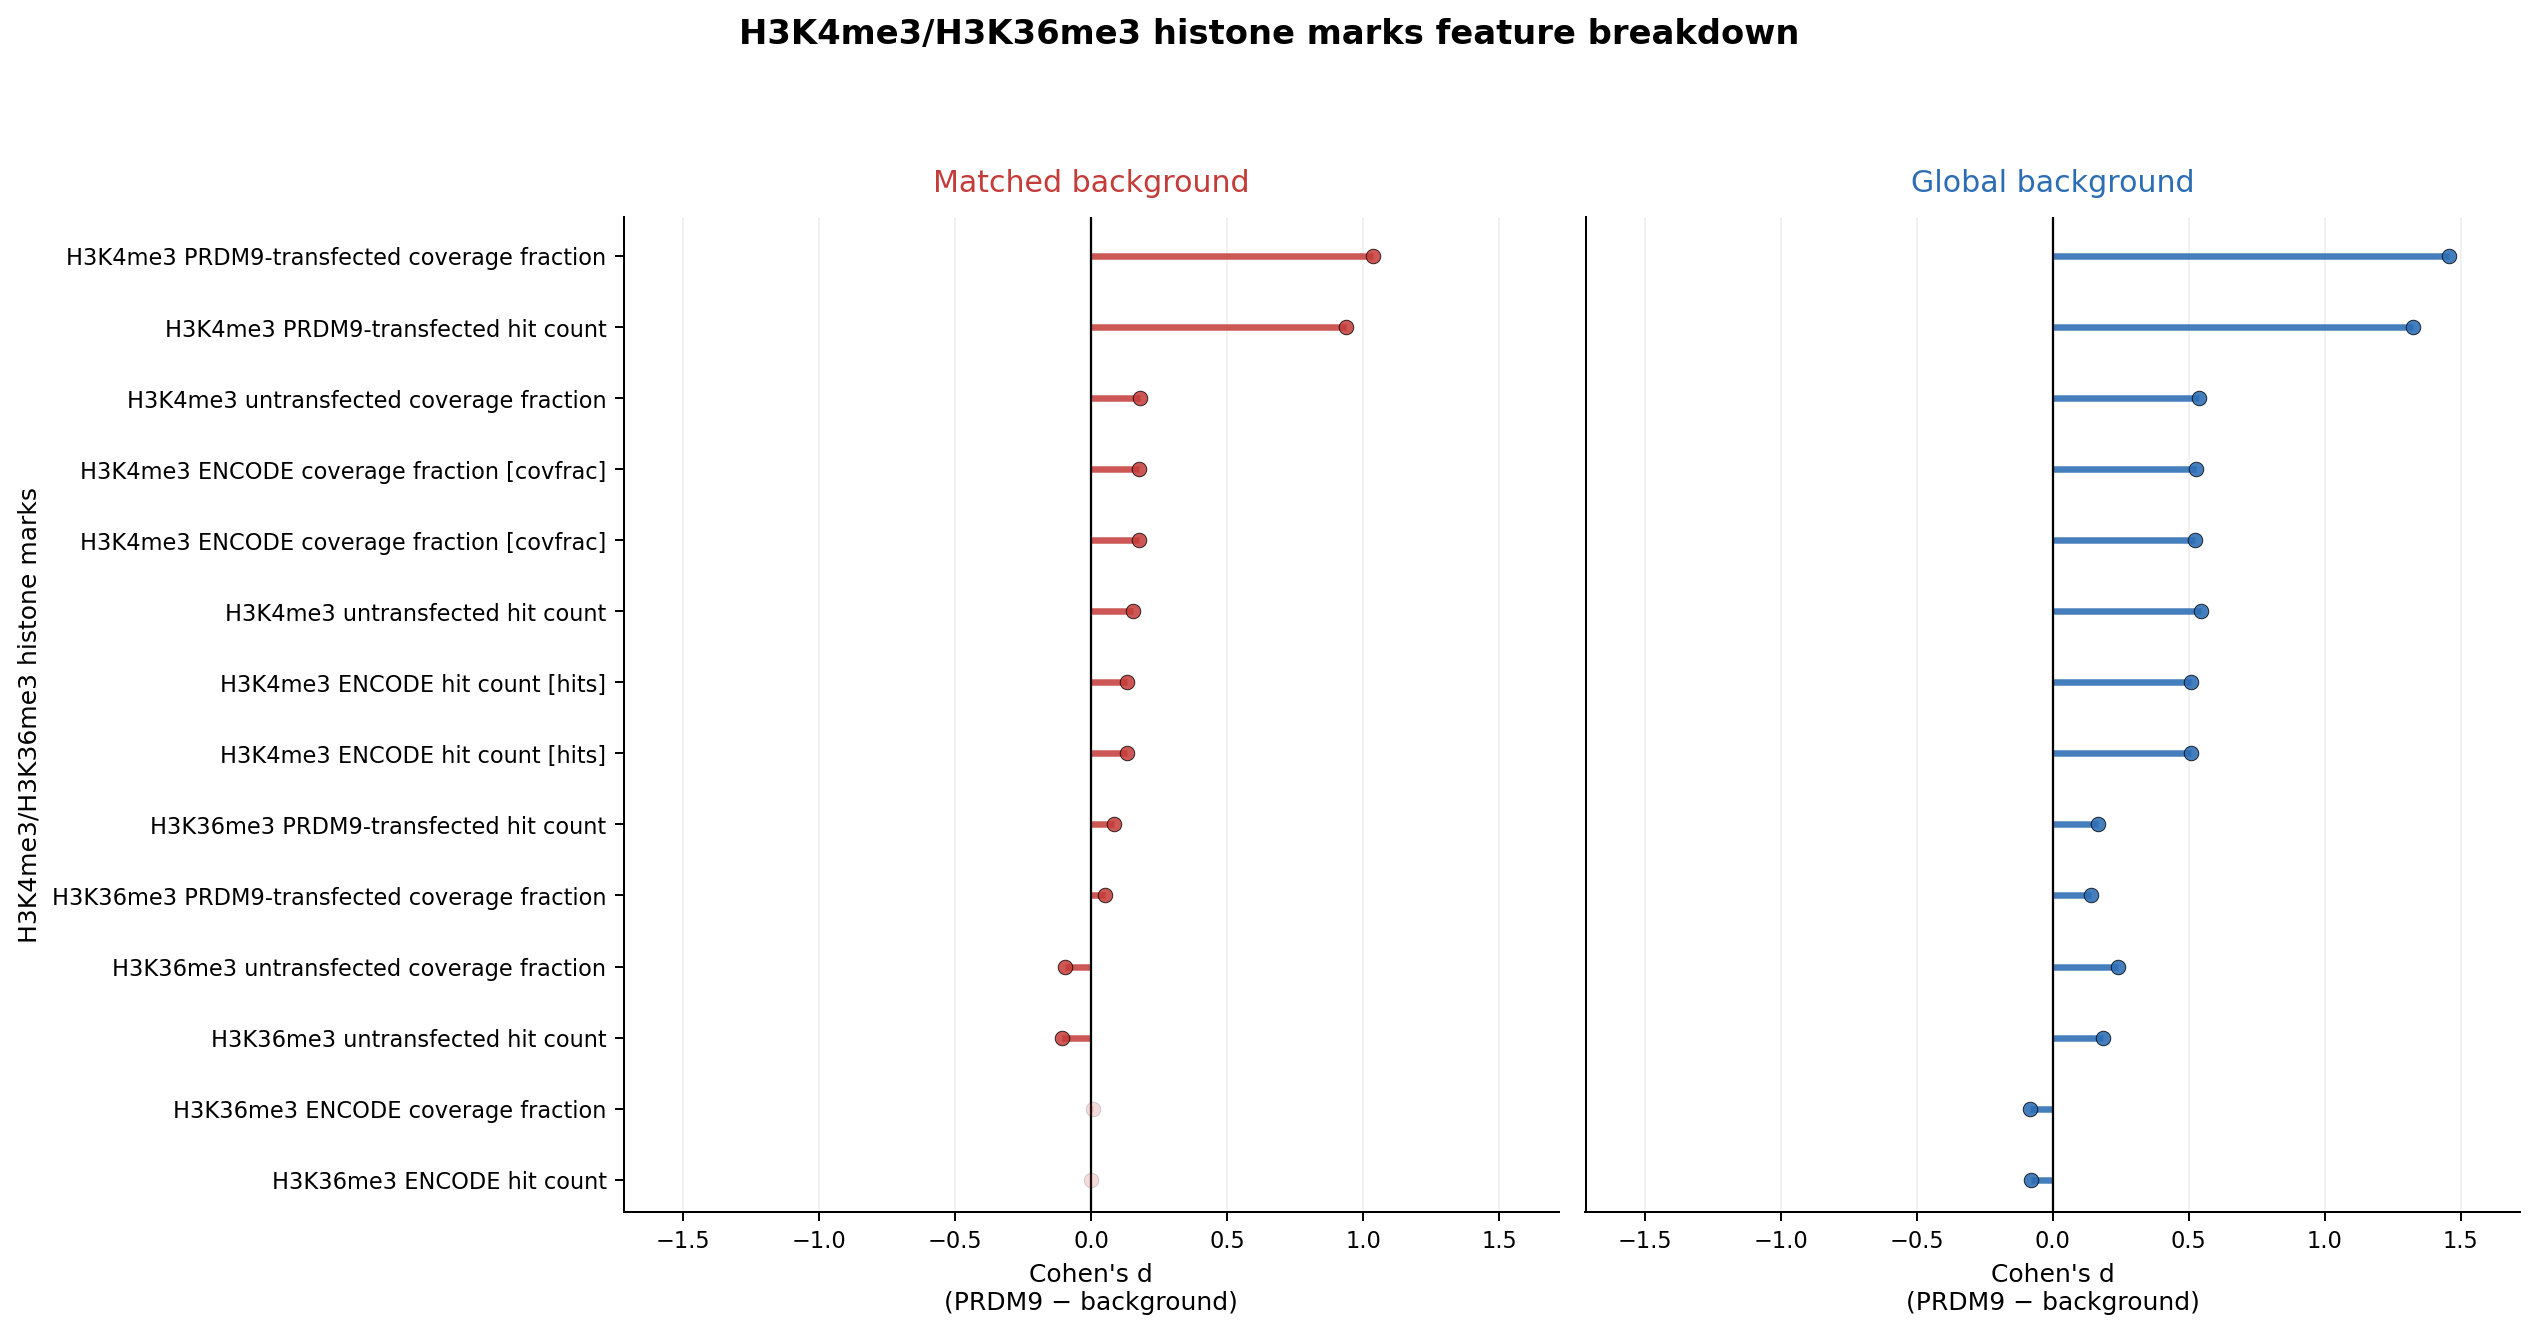

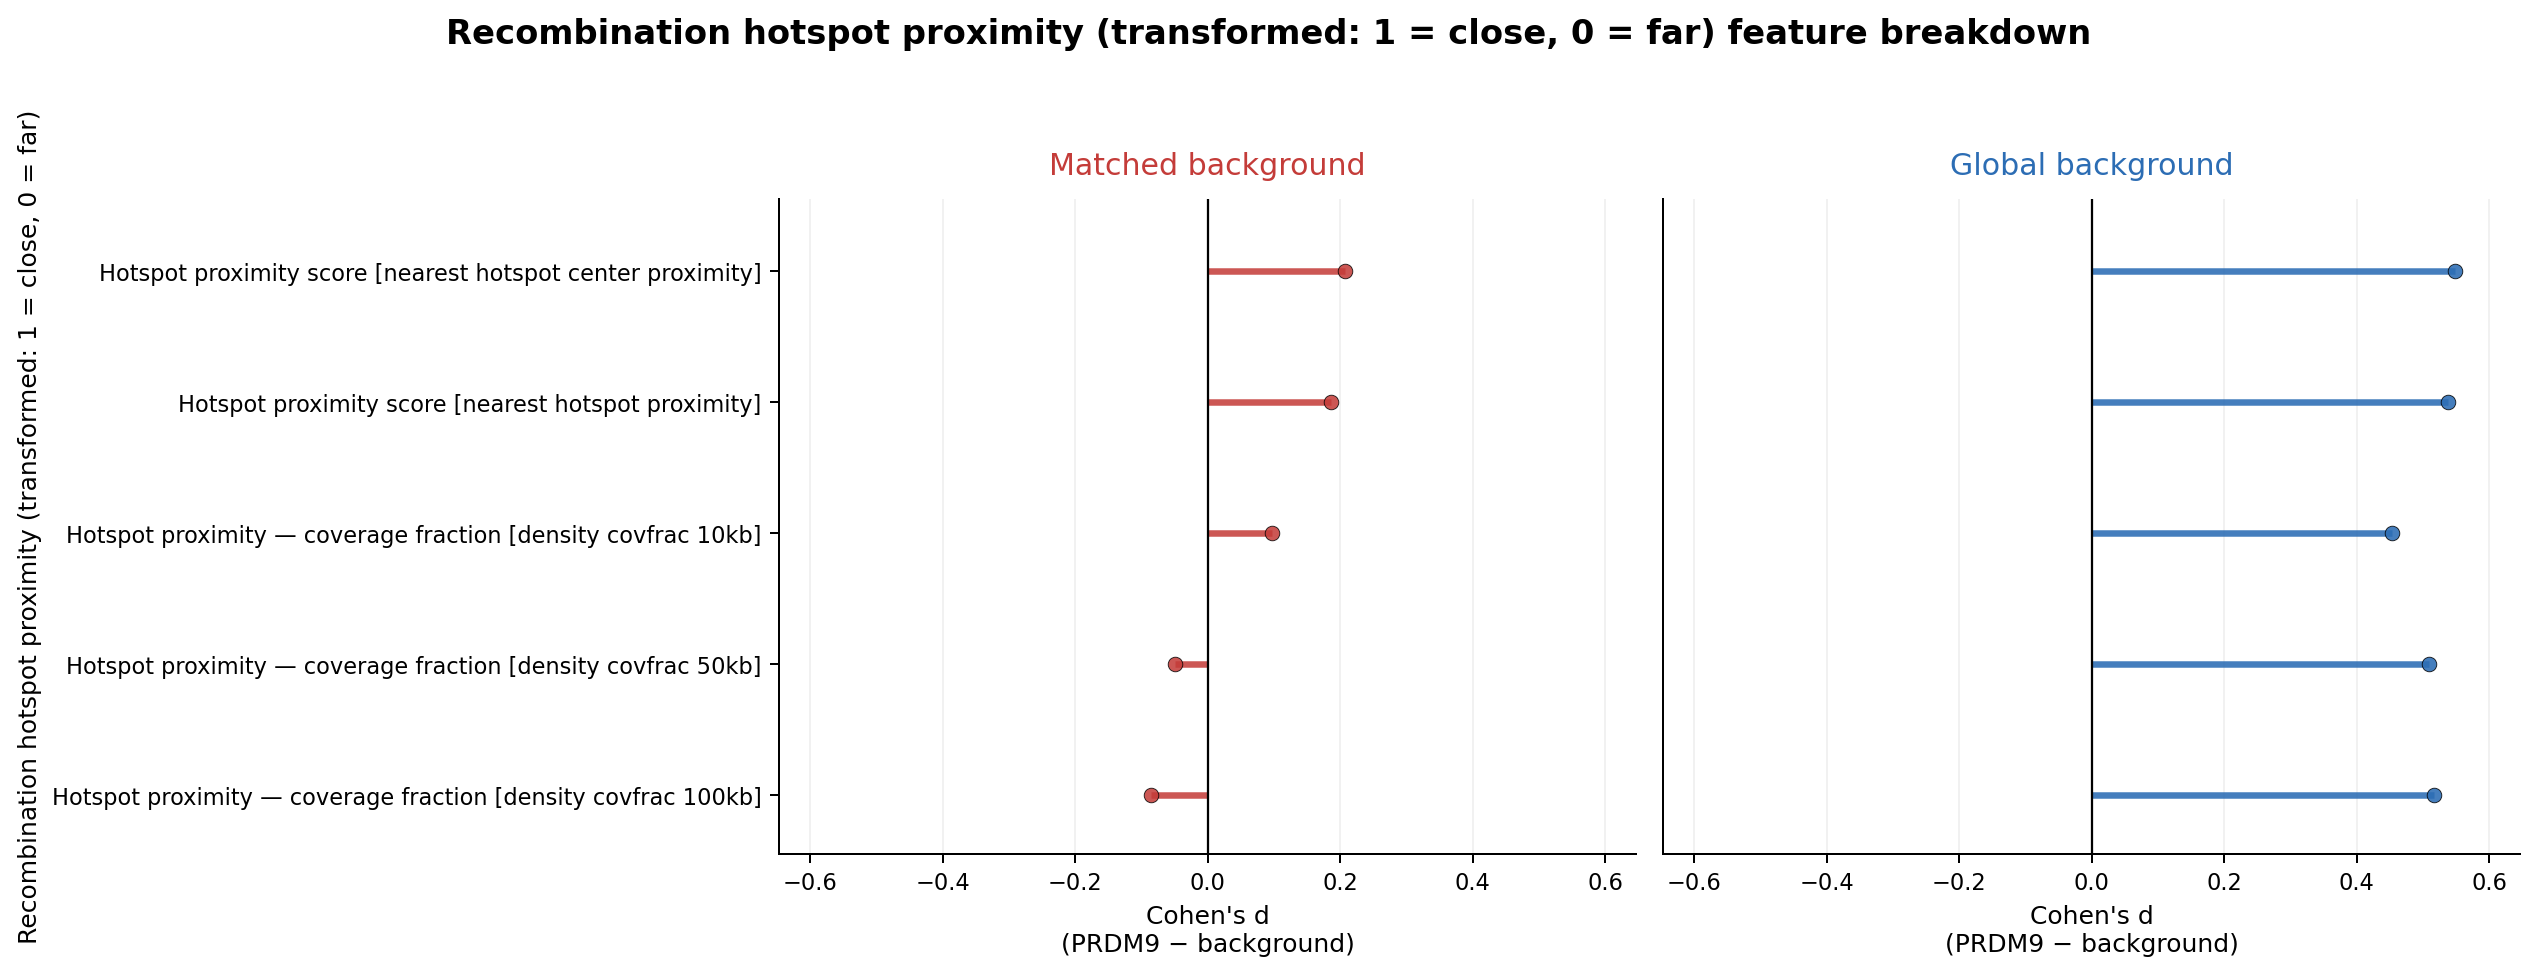

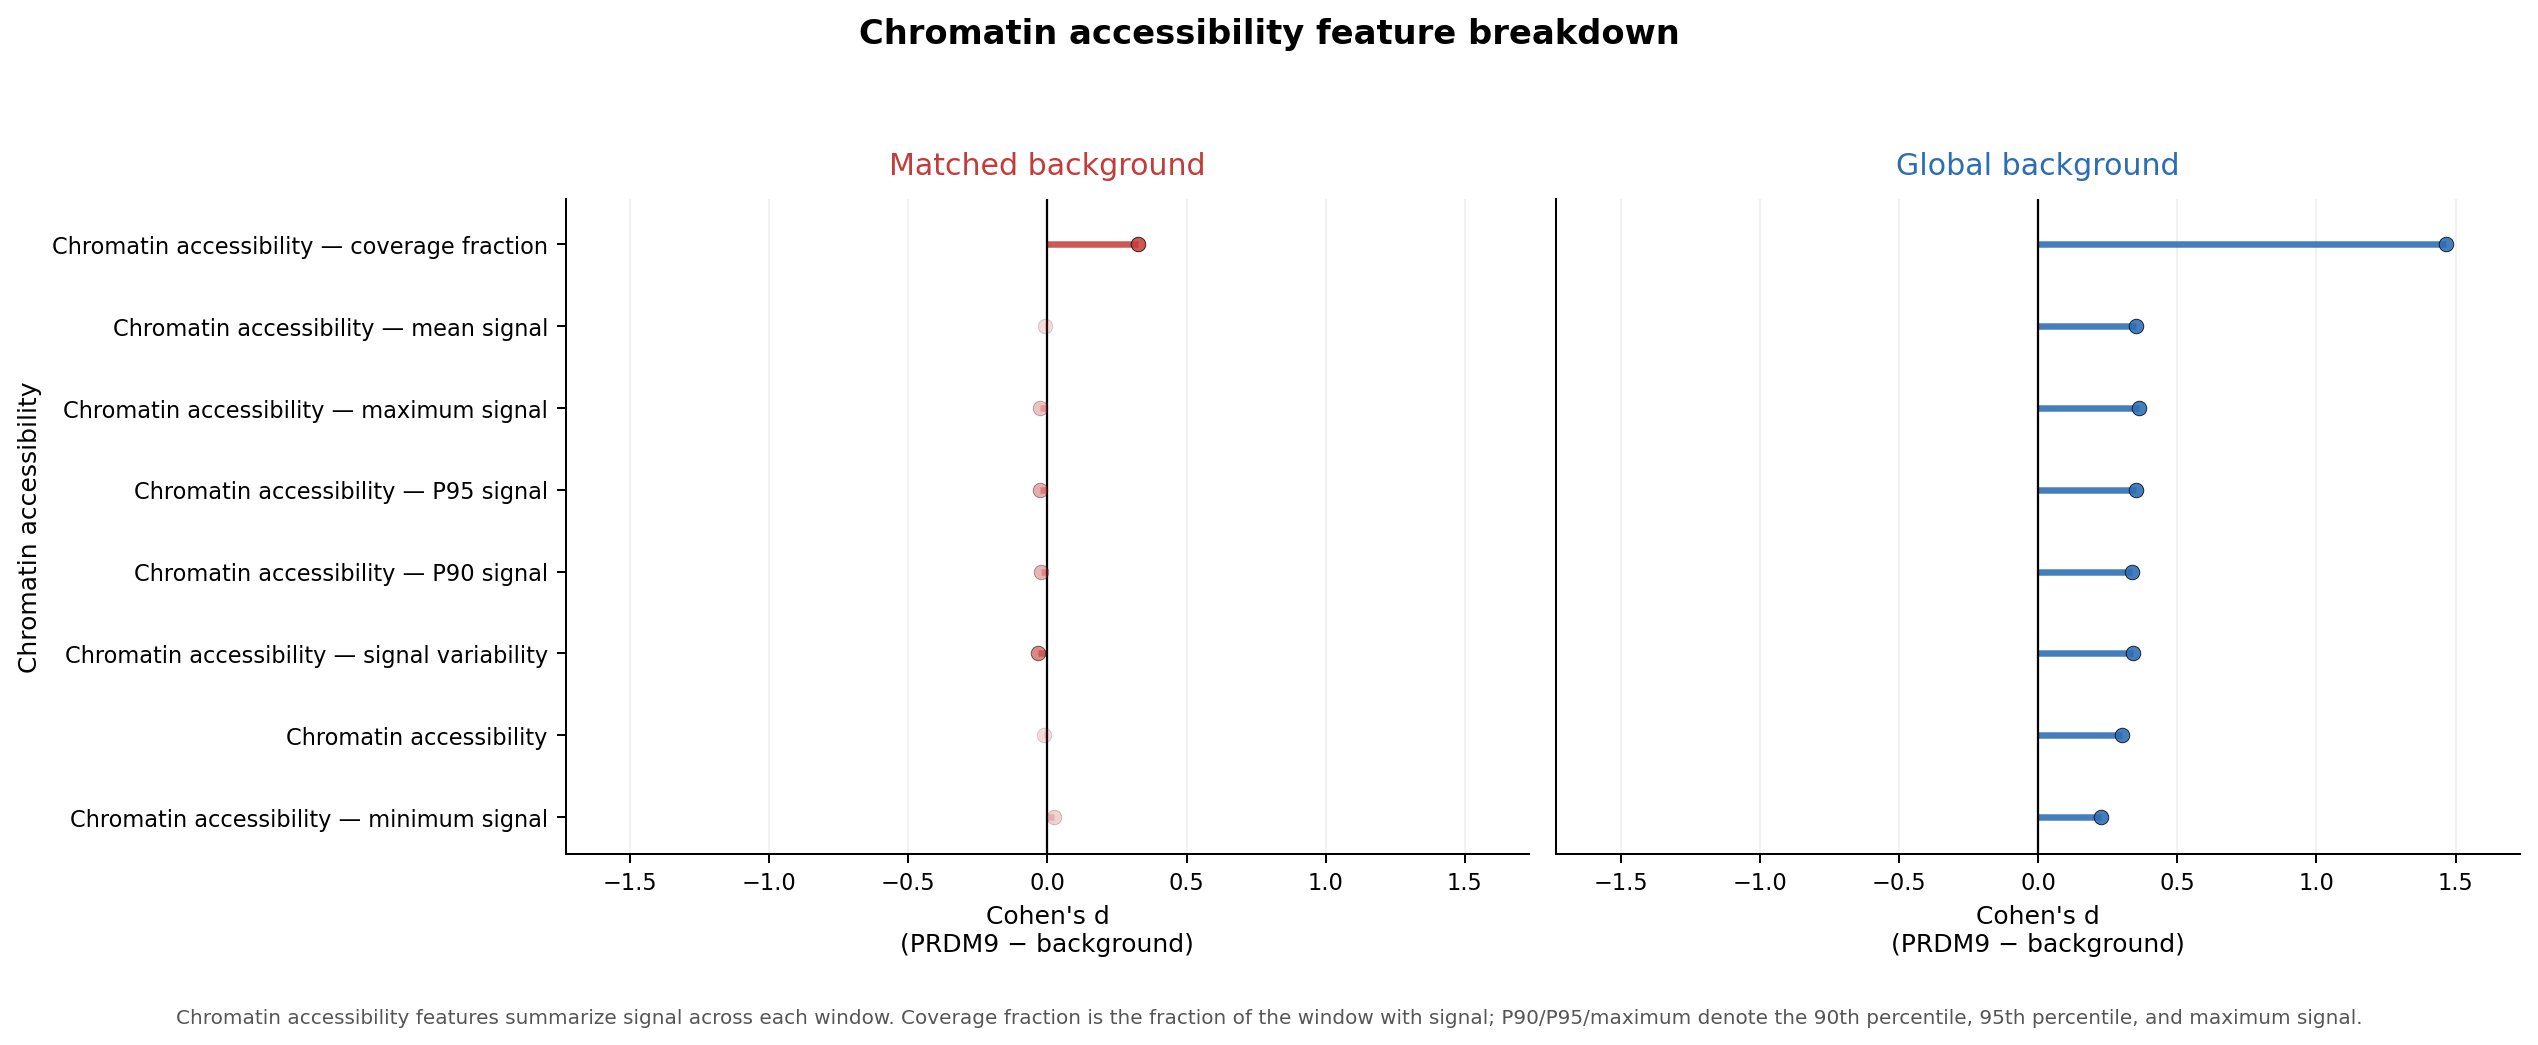

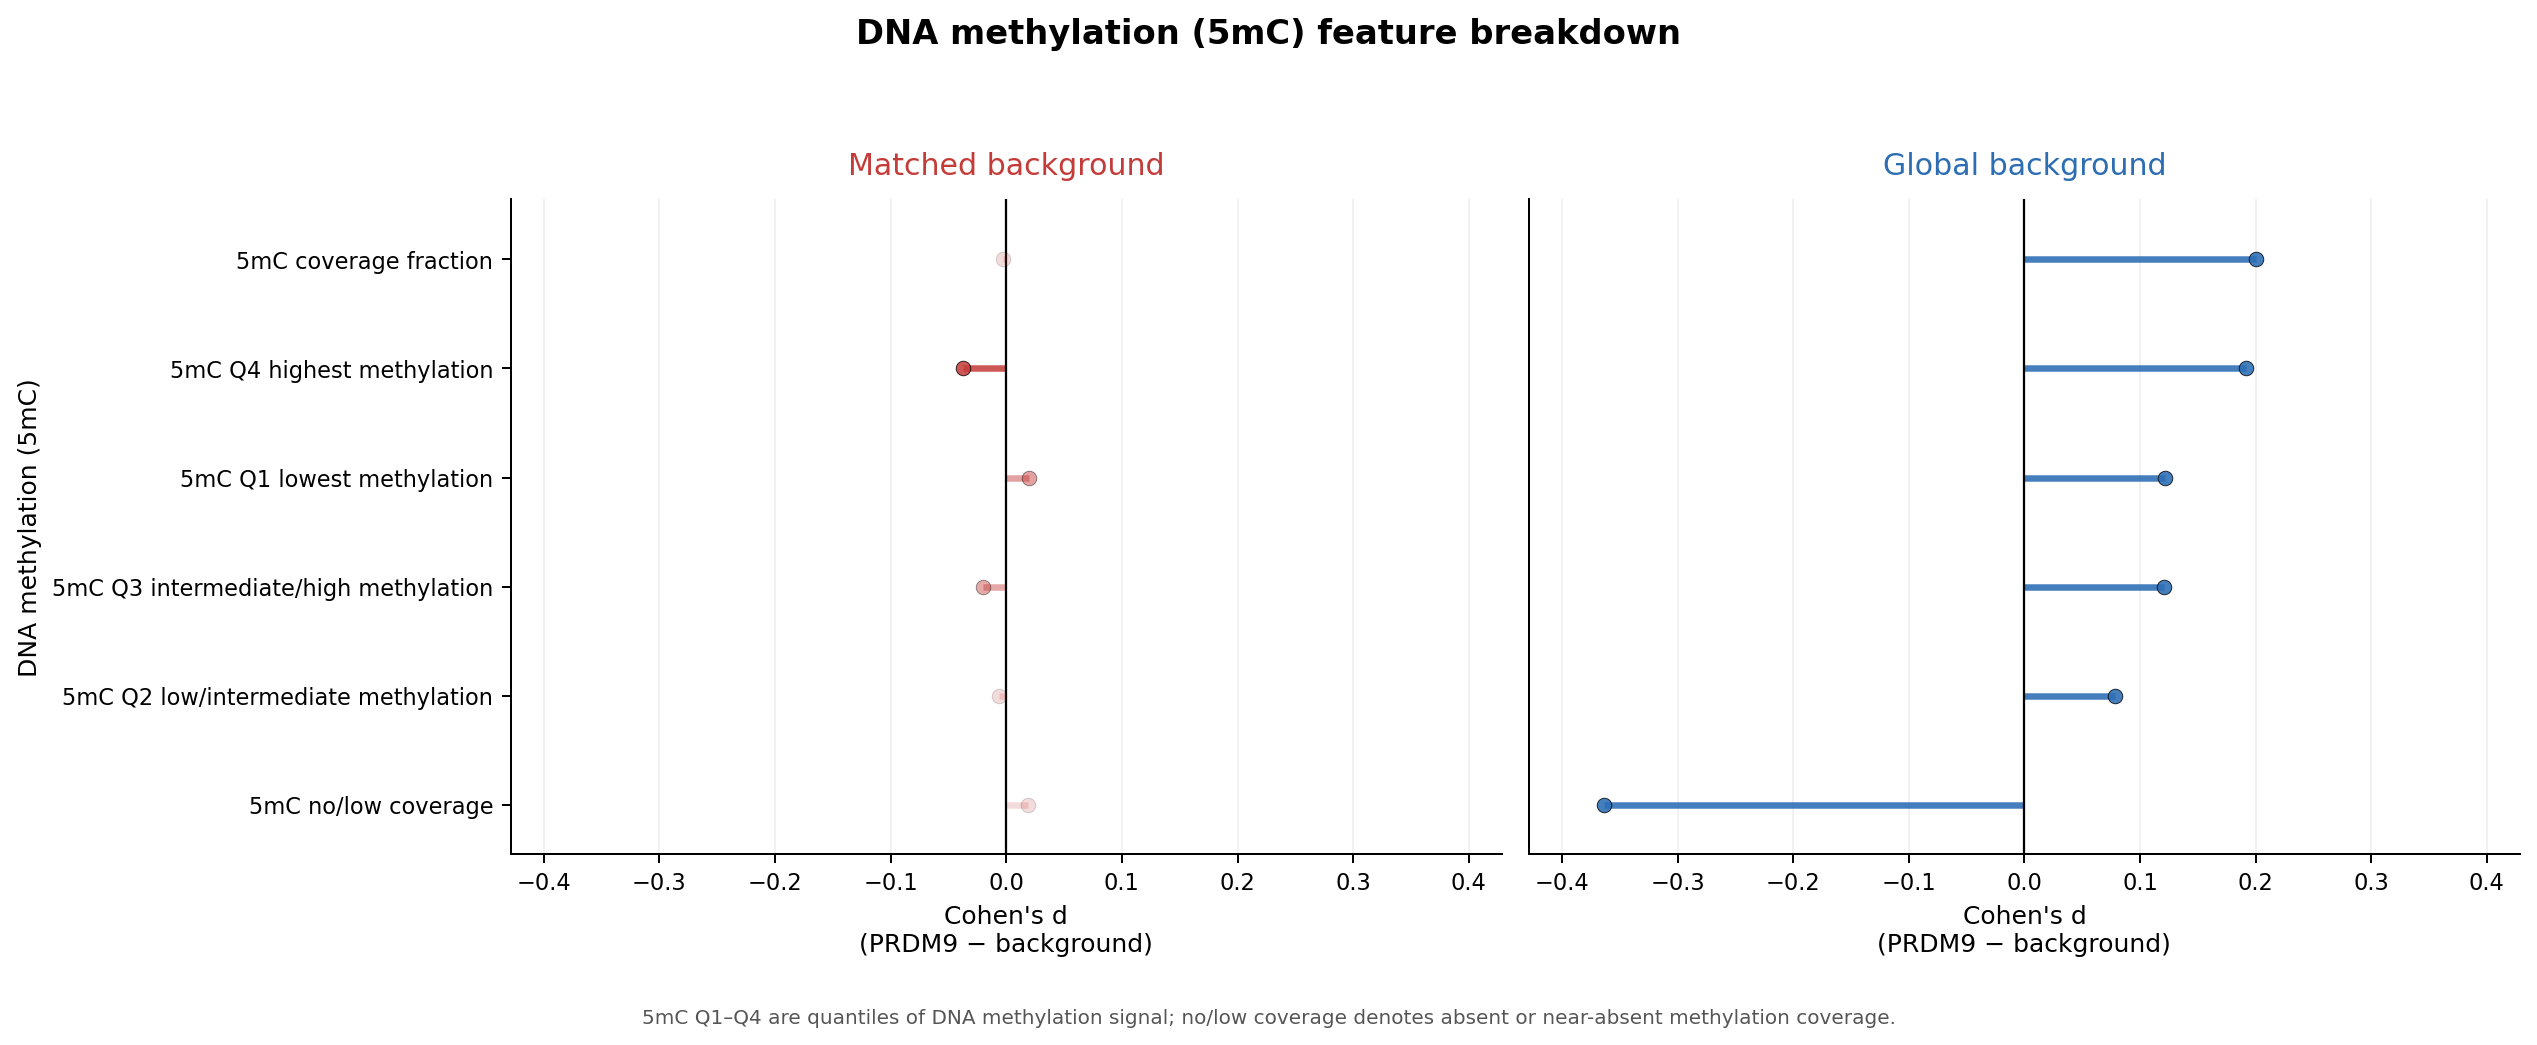

In [56]:
# ------------------------------------------------------------------
# Per-class breakdown figures — curated publication version
# ------------------------------------------------------------------
def make_block_breakdown_figures_publication(res_a, res_b, out_dir):
    # G4 breakdown is intentionally omitted: the aggregated G4 panels already
    # carry the interpretable signal, while the per-feature G4 breakdown is noisy
    # and visually misleading.
    breakdown_blocks = [b for b in PLOT_BLOCK_ORDER if b != "g4"]

    for block in breakdown_blocks:
        sub_a = res_a.loc[res_a["block"].astype(str) == block].copy()
        sub_b = res_b.loc[res_b["block"].astype(str) == block].copy()
        if sub_a.empty and sub_b.empty:
            continue

        merged = (
            sub_a[["feature", "cohens_d", "fdr_final"]]
            .rename(columns={"cohens_d": "cohens_d_A", "fdr_final": "fdr_final_A"})
            .merge(
                sub_b[["feature", "cohens_d", "fdr_final"]]
                .rename(columns={"cohens_d": "cohens_d_B", "fdr_final": "fdr_final_B"}),
                on="feature",
                how="outer",
            )
        )

        merged[["cohens_d_A", "cohens_d_B"]] = merged[["cohens_d_A", "cohens_d_B"]].fillna(0.0)
        merged[["fdr_final_A", "fdr_final_B"]] = merged[["fdr_final_A", "fdr_final_B"]].fillna(1.0)
        merged["min_fdr"] = np.minimum(merged["fdr_final_A"], merged["fdr_final_B"])
        merged["rank_strength"] = np.maximum(np.abs(merged["cohens_d_A"]), np.abs(merged["cohens_d_B"]))
        merged["mean_effect"] = merged[["cohens_d_A", "cohens_d_B"]].mean(axis=1)

        # Motif-specific display curation:
        # keep coverage-fraction features, remove raw hit-count features.
        # This does not alter the analysis table; it only changes what is shown.
        if block == "motifs":
            f = merged["feature"].astype(str).str.lower()
            is_coverage_fraction = (
                f.str.contains("covfrac", regex=False)
                | f.str.contains("coverage_fraction", regex=False)
                | f.str.contains("coverage_frac", regex=False)
                | f.str.contains("fraction_covered", regex=False)
                | f.str.contains("covered_fraction", regex=False)
            )
            is_hits = (
                f.str.contains("hits", regex=False)
                | f.str.contains("hit_count", regex=False)
                | f.str.contains("n_hits", regex=False)
                | f.str.contains("count", regex=False)
            )
            merged = merged.loc[is_coverage_fraction & ~is_hits].copy()

        if merged.empty:
            print(f"[breakdown] Skipping {block}: no displayable features after figure-only filtering.")
            continue

        # Same visual purpose as before: show strongest significant/extreme features.
        panel = (
            merged.sort_values(["min_fdr", "rank_strength"], ascending=[True, False], kind="mergesort")
            .head(2 * TOP_BREAKDOWN_PER_DIRECTION)
            .copy()
        )

        if panel.empty:
            continue

        panel = (
            panel.sort_values(["mean_effect", "rank_strength"], ascending=[False, False], kind="mergesort")
            .reset_index(drop=True)
        )
        panel["public_feature"] = _make_unique_labels(panel["feature"])

        fig_h = max(5.8, 0.40 * len(panel) + 2.35)
        fig, axes = plt.subplots(1, 2, figsize=(14.2, fig_h), sharey=True)

        y = np.arange(len(panel))
        xlim_abs = max(
            0.25,
            float(np.nanmax(np.abs(panel[["cohens_d_A", "cohens_d_B"]].to_numpy(dtype=np.float64)))) * 1.18,
        )

        for ax, comp_name, effect_col, fdr_col, color in [
            (axes[0], "Matched background", "cohens_d_A", "fdr_final_A", DATASET_COLORS["datasetA_matched"]),
            (axes[1], "Global background", "cohens_d_B", "fdr_final_B", DATASET_COLORS["datasetB_global"]),
        ]:
            effects = panel[effect_col].to_numpy(dtype=np.float64)
            fdrs = panel[fdr_col].to_numpy(dtype=np.float64)
            fdrs = np.where(np.isfinite(fdrs), fdrs, 1.0)
            fdrs = np.clip(fdrs, 1e-300, 1.0)
            shades = np.clip(-np.log10(fdrs) / 6.0, 0.18, 1.0)

            for yi, eff, shade in zip(y, effects, shades):
                ax.hlines(yi, 0, eff, color=color, alpha=float(shade), lw=2.6)
                ax.scatter(
                    [eff],
                    [yi],
                    s=34,
                    color=color,
                    alpha=float(shade),
                    edgecolor="black",
                    linewidth=0.35,
                    zorder=3,
                )

            ax.axvline(0, color="black", lw=0.9)
            ax.grid(True, axis="x", alpha=0.20, lw=0.65)
            ax.set_xlim(-xlim_abs, xlim_abs)
            ax.set_title(comp_name, color=color, pad=10)
            ax.set_xlabel("Cohen's d\n(PRDM9 − background)")
            ax.set_yticks(y)

            # Avoid shared-axis label deletion: labels only on left, but not wiped globally.
            if ax is axes[0]:
                ax.set_yticklabels(panel["public_feature"].tolist())
                ax.tick_params(axis="y", labelleft=True)
            else:
                ax.tick_params(axis="y", labelleft=False, left=False)

            ax.set_ylim(len(panel) - 0.55, -0.55)
            _despine(ax)

        axes[0].set_ylabel(PUBLIC_BLOCK_LABELS[block].replace("\n", " "))

        fig.suptitle(
            f"{PUBLIC_BLOCK_LABELS[block].replace(chr(10), ' ')} feature breakdown",
            y=0.985,
            fontsize=13.5,
            fontweight="bold",
        )
        fig.text(
            0.5,
            0.018,
            _block_specific_note(block),
            ha="center",
            va="bottom",
            fontsize=8.0,
            color="#555555",
            wrap=True,
        )

        fig.tight_layout(rect=[0, 0.060, 1, 0.94])
        out_path = out_dir / f"figure_breakdown_{block}_publication.png"
        _save_publication_figure(fig, out_path)
        plt.show()


make_block_breakdown_figures_publication(res_A, res_B, FIGDIR)